<a href="https://colab.research.google.com/github/2000Voli/2000Voli/blob/main/Projeto_integrado_Feature_Engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# IMPORTAÇÃO DAS BIBLIOTECAS

# Biblioteca para manipulação e análise de dados tabulares. Permite trabalhar com DataFrames, realizar filtros, agrupamentos e obter estatísticas descritivas.

import pandas as pd

# Biblioteca para operações matemáticas e numéricas. Será utilizada em cálculos e transformações de variáveis.
import numpy as np

# Biblioteca para criação de gráficos e visualizações.
import matplotlib.pyplot as plt

# Biblioteca para visualização estatística dos dados.
import seaborn as sns

# Configuração para exibir todas as colunas dos DataFrames. Facilita a inspeção de datasets com muitas variáveis.
pd.set_option("display.max_columns", None)

# Configuração para melhorar a leitura de valores numéricos. Exibe números com duas casas decimais.
pd.set_option("display.float_format", "{:.2f}".format)

print("Bibliotecas importadas com sucesso!")


Bibliotecas importadas com sucesso!


In [4]:

# CARREGAMENTO DO DATASET

# URL do dataset oficial.
url = (
    "https://raw.githubusercontent.com/diogenesjusto/"
    "FIAP/refs/heads/master/dados/"
    "credit_features_formatado.csv"
)

# Leitura do arquivo CSV.
df = pd.read_csv(url, low_memory=False)

# Remoção de coluna de índice gerada na exportação do CSV. Essa coluna não representa uma característica do cliente.
df = df.drop(columns=["Unnamed: 0"])

# Padronização do nome da variável-alvo.

# Interpretação:
# 0 = Bom pagador
# 1 = Mau pagador
df = df.rename(
    columns={"ROTULO_ALVO_MAU=1": "ROTULO_ALVO_MAU"}
)

# Verificação das dimensões do dataset.
print("Dataset carregado com sucesso!")
print(f"Quantidade de registros: {df.shape[0]}")
print(f"Quantidade de variáveis: {df.shape[1]}")

# Visualização dos cinco primeiros registros.
display(df.head())


Dataset carregado com sucesso!
Quantidade de registros: 50000
Quantidade de variáveis: 54


,ID_CLIENTE,TIPO_FUNCIONARIO,DIA_PAGAMENTO,TIPO_ENVIO_APLICACAO,QUANT_CARTOES_ADICIONAIS,TIPO_ENDERECO_POSTAL,SEXO,ESTADO_CIVIL,QUANT_DEPENDENTES,NIVEL_EDUCACIONAL,ESTADO_NASCIMENTO,CIDADE_NASCIMENTO,NACIONALIDADE,ESTADO_RESIDENCIAL,CIDADE_RESIDENCIAL,BAIRRO_RESIDENCIAL,FLAG_TELEFONE_RESIDENCIAL,CODIGO_AREA_TELEFONE_RESIDENCIAL,TIPO_RESIDENCIA,MESES_RESIDENCIA,FLAG_TELEFONE_MOVEL,FLAG_EMAIL,RENDA_PESSOAL_MENSAL,OUTRAS_RENDAS,FLAG_VISA,FLAG_MASTERCARD,FLAG_DINERS,FLAG_AMERICAN_EXPRESS,FLAG_OUTROS_CARTOES,QUANT_CONTAS_BANCARIAS,QUANT_CONTAS_BANCARIAS_ESPECIAIS,VALOR_PATRIMONIO_PESSOAL,QUANT_CARROS,EMPRESA,ESTADO_PROFISSIONAL,CIDADE_PROFISSIONAL,BAIRRO_PROFISSIONAL,FLAG_TELEFONE_PROFISSIONAL,CODIGO_AREA_TELEFONE_PROFISSIONAL,MESES_NO_TRABALHO,CODIGO_PROFISSAO,TIPO_OCUPACAO,CODIGO_PROFISSAO_CONJUGE,NIVEL_EDUCACIONAL_CONJUGE,FLAG_DOCUMENTO_RESIDENCIAL,FLAG_RG,FLAG_CPF,FLAG_COMPROVANTE_RENDA,PRODUTO,FLAG_REGISTRO_ACSP,IDADE,CEP_RESIDENCIAL_3,CEP_PROFISSIONAL_3,ROTULO_ALVO_MAU
0,1,C,5,Web,0,1,F,6,1,0,RN,Assu,1,RN,Santana do Matos,Centro,Y,105,1.00,15.00,N,1,900.00,0.00,1,1,0,0,0,0,0,0.00,0,N,,NaN,NaN,N,,0,9.00,4.00,NaN,NaN,0,0,0,0,1,N,32,595,595,1
1,2,C,15,Carga,0,1,F,2,0,0,RJ,rio de janeiro,1,RJ,RIO DE JANEIRO,CAMPO GRANDE,Y,20,1.00,1.00,N,1,750.00,0.00,0,0,0,0,0,0,0,0.00,0,Y,,NaN,NaN,N,,0,11.00,4.00,11.00,NaN,0,0,0,0,1,N,34,230,230,1
2,3,C,5,Web,0,1,F,2,0,0,RN,GARANHUNS,1,RN,Parnamirim,Boa Esperanca,Y,105,1.00,NaN,N,1,500.00,0.00,0,0,0,0,0,0,0,0.00,0,N,,NaN,NaN,N,,0,11.00,NaN,NaN,NaN,0,0,0,0,1,N,27,591,591,0
3,4,C,20,Web,0,1,F,2,0,0,PE,CABO,1,PE,CABO,PONTE DOS CARVALHOS,N,,NaN,NaN,N,1,500.00,0.00,0,0,0,0,0,0,0,0.00,0,N,,NaN,NaN,N,,0,NaN,NaN,NaN,NaN,0,0,0,0,1,N,61,545,545,0
4,5,C,10,Web,0,1,M,2,0,0,RJ,RIO DE JANEIRO,1,RJ,Rio de Janeiro,Santa Cruz,Y,20,1.00,12.00,N,1,1200.00,0.00,0,0,0,0,0,0,0,0.00,0,N,,NaN,NaN,N,,0,9.00,5.00,NaN,NaN,0,0,0,0,1,N,48,235,235,1


In [6]:

# Identificar os tipos de dados e quantificar os valores ausentes em cada variável.

# Quantidade total de registros do dataset.
total_registros = len(df)

# Construção de uma tabela de diagnóstico por variável.
diagnostico = pd.DataFrame({
    "Tipo de dado": df.dtypes.astype(str),
    "Valores preenchidos": df.notna().sum(),
    "Valores ausentes": df.isna().sum(),
    "Percentual ausente (%)": (
        df.isna().sum() / total_registros * 100
    ).round(2)
})

# Ordenação das variáveis pelo percentual de ausência.
diagnostico = diagnostico.sort_values(
    by="Percentual ausente (%)",
    ascending=False
)

# Exibição das variáveis com valores ausentes.
print("VARIÁVEIS COM VALORES AUSENTES")

display(
    diagnostico[
        diagnostico["Valores ausentes"] > 0
    ]
)

# Resumo geral da qualidade dos dados.
print("\nRESUMO GERAL")

print(f"Total de registros: {df.shape[0]}")
print(f"Total de variáveis: {df.shape[1]}")

print(
    "Variáveis com valores ausentes:",
    (df.isna().sum() > 0).sum()
)

print(
    "Total de células ausentes:",
    df.isna().sum().sum()
)


VARIÁVEIS COM VALORES AUSENTES


,Tipo de dado,Valores preenchidos,Valores ausentes,Percentual ausente (%)
BAIRRO_PROFISSIONAL,object,16217,33783,67.57
CIDADE_PROFISSIONAL,object,16217,33783,67.57
NIVEL_EDUCACIONAL_CONJUGE,float64,17662,32338,64.68
CODIGO_PROFISSAO_CONJUGE,float64,21116,28884,57.77
CODIGO_PROFISSAO,float64,42244,7756,15.51
TIPO_OCUPACAO,float64,42687,7313,14.63
MESES_RESIDENCIA,float64,46223,3777,7.55
TIPO_RESIDENCIA,float64,48651,1349,2.70



RESUMO GERAL
Total de registros: 50000
Total de variáveis: 54
Variáveis com valores ausentes: 8
Total de células ausentes: 148983


DISTRIBUIÇÃO DA INADIMPLÊNCIA


,Quantidade,Percentual (%)
Bom pagador,36959,73.92
Mau pagador,13041,26.08


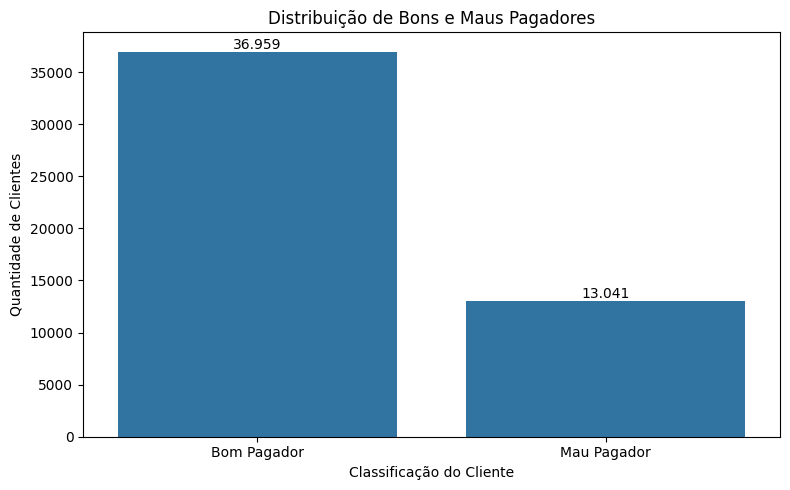

In [7]:
# Analisar a proporção de bons e maus pagadores.

# Contagem absoluta de clientes por classe.
contagem = (
    df["ROTULO_ALVO_MAU"]
    .value_counts()
    .sort_index()
)

# Distribuição percentual por classe.
percentual = (
    df["ROTULO_ALVO_MAU"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

# Tabela de distribuição.
distribuicao = pd.DataFrame({
    "Quantidade": contagem,
    "Percentual (%)": percentual.round(2)
})

# Identificação das classes.
distribuicao.index = [
    "Bom pagador",
    "Mau pagador"
]

print("DISTRIBUIÇÃO DA INADIMPLÊNCIA")
display(distribuicao)

# Visualização gráfica.
plt.figure(figsize=(8, 5))

grafico = sns.countplot(
    data=df,
    x="ROTULO_ALVO_MAU",
    order=[0, 1]
)

# Exibição das quantidades sobre as barras.
for barra in grafico.patches:
    altura = barra.get_height()

    grafico.annotate(
        f"{int(altura):,}".replace(",", "."),
        (
            barra.get_x() + barra.get_width() / 2,
            altura
        ),
        ha="center",
        va="bottom"
    )

plt.title("Distribuição de Bons e Maus Pagadores")
plt.xlabel("Classificação do Cliente")
plt.ylabel("Quantidade de Clientes")
plt.xticks([0, 1], ["Bom Pagador", "Mau Pagador"])

plt.tight_layout()
plt.show()


In [8]:
# Analisar o comportamento das principais variáveis quantitativas do dataset.

# Seleção das variáveis quantitativas de interesse.
variaveis_numericas = [
    "IDADE",
    "RENDA_PESSOAL_MENSAL",
    "OUTRAS_RENDAS",
    "VALOR_PATRIMONIO_PESSOAL",
    "MESES_RESIDENCIA",
    "MESES_NO_TRABALHO",
    "QUANT_DEPENDENTES",
    "QUANT_CONTAS_BANCARIAS"
]


# 1. Estatísticas descritivas
estatisticas = (
    df[variaveis_numericas]
    .describe()
    .T
    .round(2)
)

print("ESTATÍSTICAS DESCRITIVAS")
display(estatisticas)

# 2. Análise de valores iguais a zero

quantidade_zeros = (
    (df[variaveis_numericas] == 0)
    .sum()
)

# Calcula o percentual de zeros em relação ao total de registros do dataset.

percentual_zeros = (
    quantidade_zeros / len(df) * 100
).round(2)

# Organiza os resultados em uma tabela.

analise_zeros = pd.DataFrame({
    "Quantidade de zeros": quantidade_zeros,
    "Percentual de zeros (%)": percentual_zeros
})

# Ordena da maior para a menor quantidade de zeros.

analise_zeros = analise_zeros.sort_values(
    by="Quantidade de zeros",
    ascending=False
)

print("\nANÁLISE DE VALORES IGUAIS A ZERO")
display(analise_zeros)


ESTATÍSTICAS DESCRITIVAS


,count,mean,std,min,25%,50%,75%,max
IDADE,50000.00,43.25,14.99,6.00,31.00,41.00,53.00,106.00
RENDA_PESSOAL_MENSAL,50000.00,886.68,7846.96,60.00,360.00,500.00,800.00,959000.00
OUTRAS_RENDAS,50000.00,35.43,891.52,0.00,0.00,0.00,0.00,194344.00
VALOR_PATRIMONIO_PESSOAL,50000.00,2322.37,42357.98,0.00,0.00,0.00,0.00,6000000.00
MESES_RESIDENCIA,46223.00,9.73,10.67,0.00,1.00,6.00,15.00,228.00
MESES_NO_TRABALHO,50000.00,0.01,0.38,0.00,0.00,0.00,0.00,35.00
QUANT_DEPENDENTES,50000.00,0.65,1.19,0.00,0.00,0.00,1.00,53.00
QUANT_CONTAS_BANCARIAS,50000.00,0.36,0.48,0.00,0.00,0.00,1.00,2.00



ANÁLISE DE VALORES IGUAIS A ZERO


,Quantidade de zeros,Percentual de zeros (%)
MESES_NO_TRABALHO,49924,99.85
VALOR_PATRIMONIO_PESSOAL,47609,95.22
OUTRAS_RENDAS,47227,94.45
QUANT_DEPENDENTES,33655,67.31
QUANT_CONTAS_BANCARIAS,32122,64.24
MESES_RESIDENCIA,4695,9.39
IDADE,0,0.00
RENDA_PESSOAL_MENSAL,0,0.00


In [9]:

# Investigar registros com valores potencialmente inconsistentes ou extremos.


# 1. Investigação da idade

print("CLIENTES COM IDADE INFERIOR A 18 ANOS")

menores_18 = df[df["IDADE"] < 18]

print("Quantidade:", len(menores_18))

display(
    menores_18[
        ["ID_CLIENTE", "IDADE", "ROTULO_ALVO_MAU"]
    ].head(10)
)

print("\nCLIENTES COM IDADE SUPERIOR A 100 ANOS")

maiores_100 = df[df["IDADE"] > 100]

print("Quantidade:", len(maiores_100))

display(
    maiores_100[
        ["ID_CLIENTE", "IDADE", "ROTULO_ALVO_MAU"]
    ].head(10)
)


# 2. Investigação da quantidade de dependentes

print("\nCLIENTES COM MAIS DE 10 DEPENDENTES")

dependentes_extremos = df[
    df["QUANT_DEPENDENTES"] > 10
]

print("Quantidade:", len(dependentes_extremos))

display(
    dependentes_extremos[
        ["ID_CLIENTE", "QUANT_DEPENDENTES",
         "ROTULO_ALVO_MAU"]
    ].head(10)
)


# 3. Investigação da renda pessoal mensal

print("\nCLIENTES COM RENDA SUPERIOR A R$ 50.000")

rendas_elevadas = df[
    df["RENDA_PESSOAL_MENSAL"] > 50000
]

print("Quantidade:", len(rendas_elevadas))

display(
    rendas_elevadas[
        ["ID_CLIENTE", "RENDA_PESSOAL_MENSAL",
         "ROTULO_ALVO_MAU"]
    ].sort_values(
        by="RENDA_PESSOAL_MENSAL",
        ascending=False
    ).head(10)
)


# 4. Investigação do tempo no trabalho

print("\nCLIENTES COM MESES NO TRABALHO DIFERENTE DE ZERO")

trabalho_nao_zero = df[
    df["MESES_NO_TRABALHO"] != 0
]

print("Quantidade:", len(trabalho_nao_zero))

display(
    trabalho_nao_zero[
        ["ID_CLIENTE", "MESES_NO_TRABALHO",
         "ROTULO_ALVO_MAU"]
    ].head(10)
)


CLIENTES COM IDADE INFERIOR A 18 ANOS
Quantidade: 21


,ID_CLIENTE,IDADE,ROTULO_ALVO_MAU
2449,2450,17,0
3103,3104,17,1
5456,5457,17,0
5529,5530,17,0
8384,8385,17,0
11305,11306,17,0
11860,11861,17,1
13158,13159,17,1
14500,14501,17,0
18155,18156,17,1



CLIENTES COM IDADE SUPERIOR A 100 ANOS
Quantidade: 3


,ID_CLIENTE,IDADE,ROTULO_ALVO_MAU
12451,12452,106,0
17803,17804,106,1
18675,18676,101,1



CLIENTES COM MAIS DE 10 DEPENDENTES
Quantidade: 22


,ID_CLIENTE,QUANT_DEPENDENTES,ROTULO_ALVO_MAU
4839,4840,13,1
4889,4890,11,0
5572,5573,13,1
7387,7388,12,0
9018,9019,14,1
15065,15066,14,0
19449,19450,15,0
21063,21064,12,0
22486,22487,11,0
26827,26828,11,0



CLIENTES COM RENDA SUPERIOR A R$ 50.000
Quantidade: 47


,ID_CLIENTE,RENDA_PESSOAL_MENSAL,ROTULO_ALVO_MAU
31053,31054,959000.00,1
48271,48272,875000.00,0
28119,28120,668000.00,1
32630,32631,486778.00,0
6501,6502,300409.00,1
11404,11405,216395.00,0
44240,44241,213063.00,0
32747,32748,198183.00,0
42748,42749,190786.00,0
39985,39986,177991.00,0



CLIENTES COM MESES NO TRABALHO DIFERENTE DE ZERO
Quantidade: 76


,ID_CLIENTE,MESES_NO_TRABALHO,ROTULO_ALVO_MAU
487,488,9,0
2498,2499,2,1
2813,2814,4,1
2825,2826,1,0
3812,3813,5,1
4243,4244,15,0
4364,4365,27,0
4710,4711,1,0
5026,5027,1,0
5531,5532,2,0


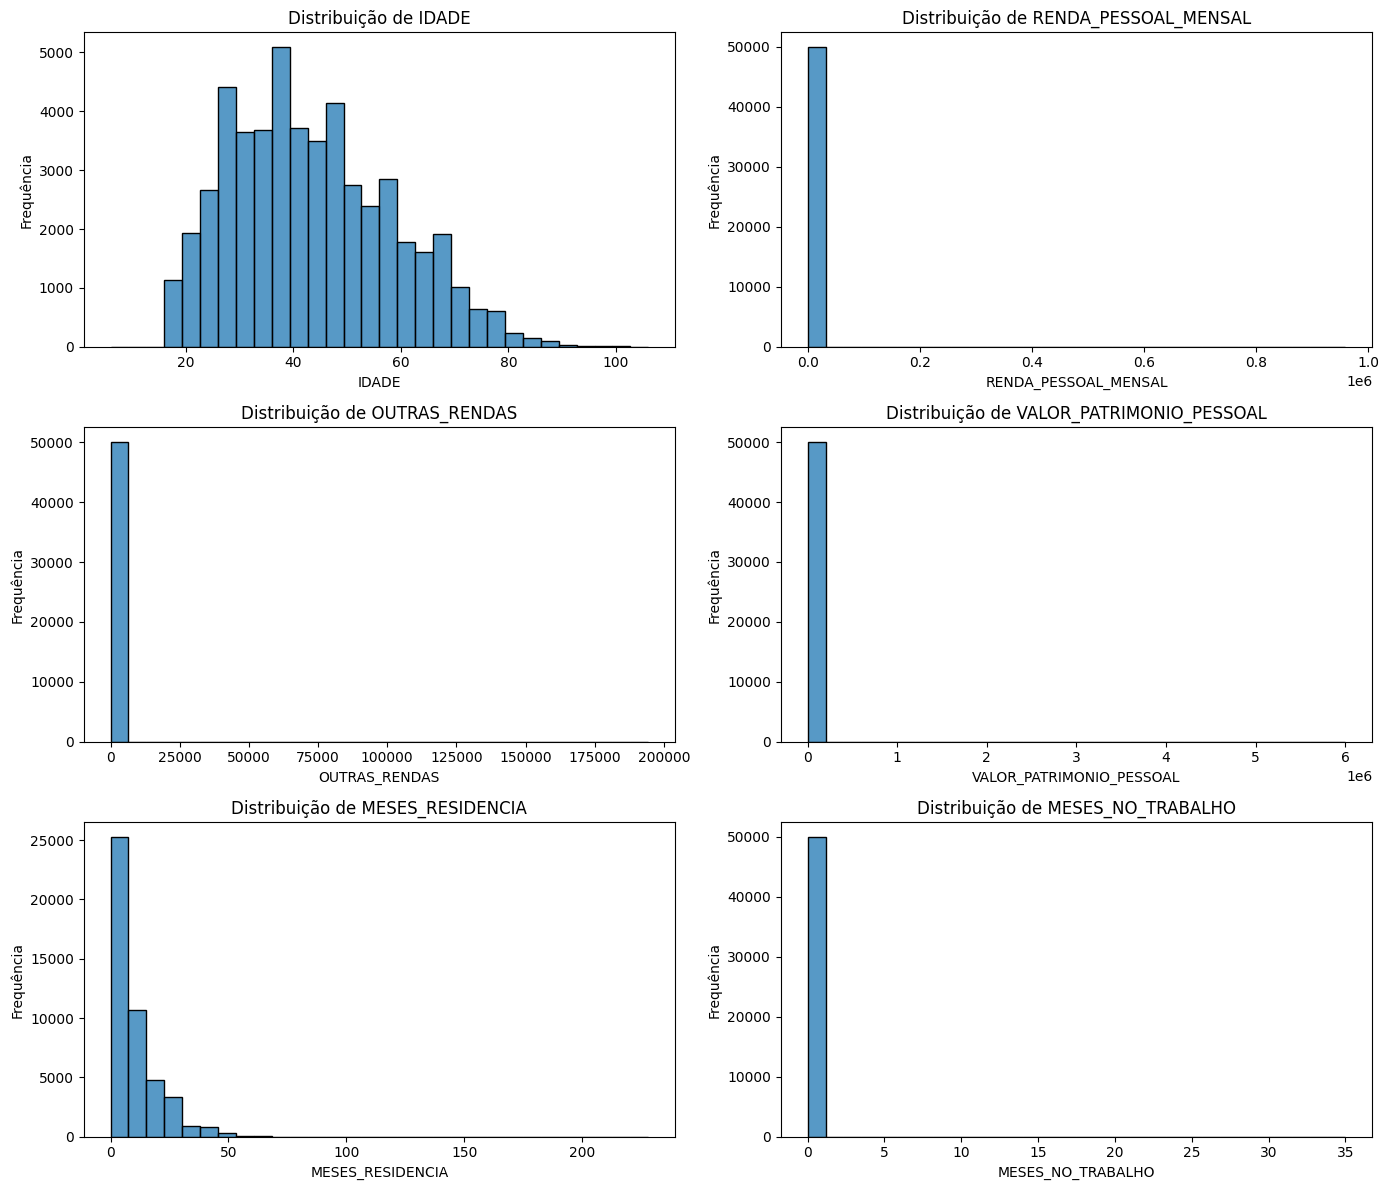

In [10]:

# Visualizar a distribuição das principais variáveis quantitativas do dataset.

# Variáveis selecionadas para análise gráfica.
variaveis_graficos = [
    "IDADE",
    "RENDA_PESSOAL_MENSAL",
    "OUTRAS_RENDAS",
    "VALOR_PATRIMONIO_PESSOAL",
    "MESES_RESIDENCIA",
    "MESES_NO_TRABALHO"
]

# Configuração da área de visualização:
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(14, 12)
)

# Transformação da matriz de eixos em uma lista, facilitando a criação dos gráficos.
axes = axes.flatten()

# Construção de um histograma para cada variável.
for i, coluna in enumerate(variaveis_graficos):

    sns.histplot(
        data=df,
        x=coluna,
        bins=30,
        ax=axes[i]
    )

    # Título e identificação dos eixos.
    axes[i].set_title(
        f"Distribuição de {coluna}"
    )

    axes[i].set_xlabel(coluna)
    axes[i].set_ylabel("Frequência")

# Ajuste automático do espaçamento.
plt.tight_layout()

# Exibição dos gráficos.
plt.show()


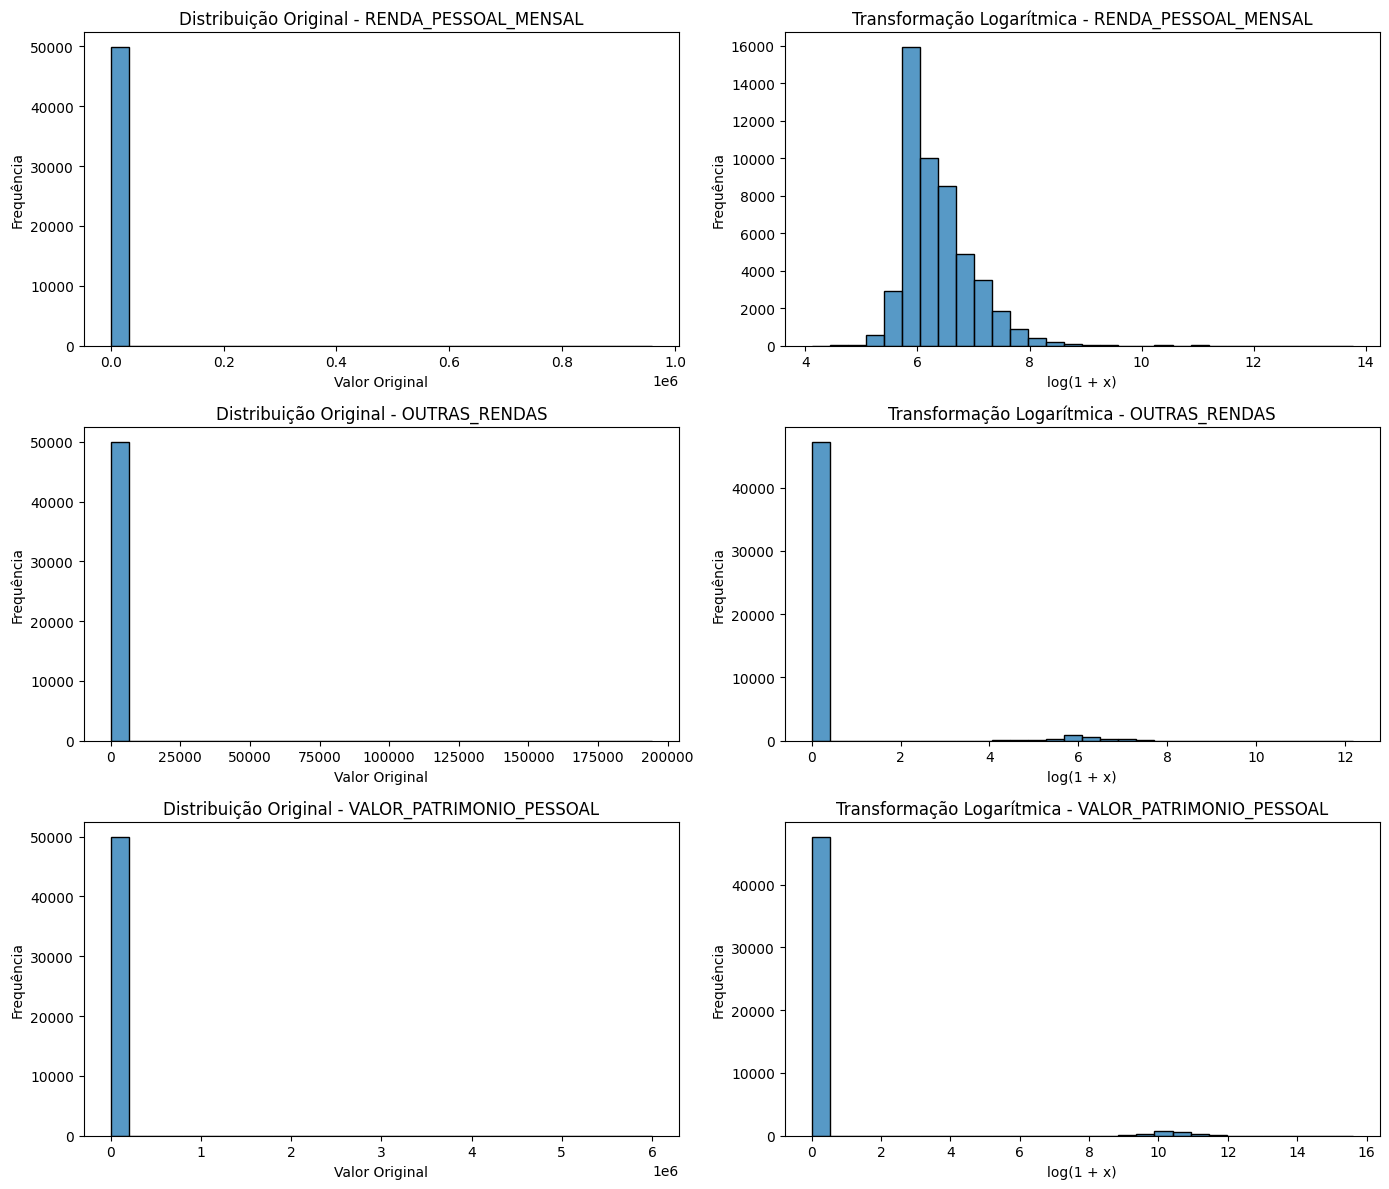

In [11]:

# Comparar visualmente as distribuições originais com as distribuições após transformação logarítmica.

# Variáveis selecionadas para comparação.
variaveis_log = [
    "RENDA_PESSOAL_MENSAL",
    "OUTRAS_RENDAS",
    "VALOR_PATRIMONIO_PESSOAL"
]

# Configuração dos gráficos:

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(14, 12)
)

# Percorre as variáveis selecionadas.
for i, coluna in enumerate(variaveis_log):


    # Distribuição original


    sns.histplot(
        df[coluna].dropna(),
        bins=30,
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(
        f"Distribuição Original - {coluna}"
    )

    axes[i, 0].set_xlabel("Valor Original")
    axes[i, 0].set_ylabel("Frequência")


    # Transformação logarítmica


    # Aplica log(1 + x) apenas para visualização. As variáveis selecionadas possuem valores não negativos.
    dados_log = np.log1p(df[coluna].dropna())

    sns.histplot(
        dados_log,
        bins=30,
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(
        f"Transformação Logarítmica - {coluna}"
    )

    axes[i, 1].set_xlabel("log(1 + x)")
    axes[i, 1].set_ylabel("Frequência")

# Ajuste do espaçamento entre os gráficos.
plt.tight_layout()

# Exibição dos resultados.
plt.show()


In [12]:
# Identificar as variáveis categóricas do dataset, analisar sua cardinalidade e verificar a frequência das categorias existentes.


# 1. Identificação das variáveis categóricas


# Seleciona as colunas armazenadas como object.
variaveis_categoricas = (
    df.select_dtypes(include=["object"])
    .columns
    .tolist()
)

print("QUANTIDADE DE VARIÁVEIS CATEGÓRICAS")
print(len(variaveis_categoricas))



# 2. Análise da cardinalidade

# Calcula a quantidade de valores distintos por variável.

cardinalidade = (
    df[variaveis_categoricas]
    .nunique(dropna=False)
    .sort_values(ascending=False)
)

# Organiza os resultados em uma tabela.
tabela_cardinalidade = pd.DataFrame({
    "Variável": cardinalidade.index,
    "Quantidade de categorias": cardinalidade.values
})

print("\nCARDINALIDADE DAS VARIÁVEIS CATEGÓRICAS")

display(tabela_cardinalidade)



# 3. Frequência das principais variáveis categóricas

# Seleção de variáveis para inspeção inicial.
variaveis_analise = [
    "TIPO_FUNCIONARIO",
    "TIPO_ENVIO_APLICACAO",
    "SEXO",
    "FLAG_TELEFONE_MOVEL",
    "FLAG_REGISTRO_ACSP"
]

# Exibe a distribuição de cada variável.
for coluna in variaveis_analise:

    print(f"\nDISTRIBUIÇÃO DE {coluna}")

    # Frequência absoluta e percentual.
    frequencia = pd.DataFrame({
        "Quantidade": df[coluna].value_counts(
            dropna=False
        ),
        "Percentual (%)": (
            df[coluna].value_counts(
                normalize=True,
                dropna=False
            ) * 100
        ).round(2)
    })

    display(frequencia)


QUANTIDADE DE VARIÁVEIS CATEGÓRICAS
20

CARDINALIDADE DAS VARIÁVEIS CATEGÓRICAS


,Variável,Quantidade de categorias
0,BAIRRO_RESIDENCIAL,14511
1,CIDADE_NASCIMENTO,9910
2,BAIRRO_PROFISSIONAL,5058
3,CIDADE_RESIDENCIAL,3529
4,CIDADE_PROFISSIONAL,2237
5,CEP_RESIDENCIAL_3,794
6,CEP_PROFISSIONAL_3,794
7,CODIGO_AREA_TELEFONE_RESIDENCIAL,102
8,CODIGO_AREA_TELEFONE_PROFISSIONAL,87
9,ESTADO_NASCIMENTO,29



DISTRIBUIÇÃO DE TIPO_FUNCIONARIO


,Quantidade,Percentual (%)
TIPO_FUNCIONARIO,,
C,50000,100.00



DISTRIBUIÇÃO DE TIPO_ENVIO_APLICACAO


,Quantidade,Percentual (%)
TIPO_ENVIO_APLICACAO,,
Web,28206,56.41
0,19461,38.92
Carga,2333,4.67


... (2 outputs left out)


DISTRIBUIÇÃO DE FLAG_TELEFONE_MOVEL


,Quantidade,Percentual (%)
FLAG_TELEFONE_MOVEL,,
N,50000,100.00



DISTRIBUIÇÃO DE FLAG_REGISTRO_ACSP


,Quantidade,Percentual (%)
FLAG_REGISTRO_ACSP,,
N,50000,100.00


In [13]:


# 1. Identificação de variáveis constantes


# Calcula a quantidade de valores distintos de todas as colunas, independentemente do tipo de dado.
quantidade_categorias = df.nunique(dropna=False)

# Seleciona variáveis com apenas um valor distinto.
variaveis_constantes = quantidade_categorias[
    quantidade_categorias == 1
].index.tolist()

print("VARIÁVEIS CONSTANTES")
print(variaveis_constantes)


# 2. Investigação de categorias específicas


variaveis_investigar = [
    "SEXO",
    "TIPO_ENVIO_APLICACAO",
    "EMPRESA",
    "ESTADO_CIVIL",
    "NIVEL_EDUCACIONAL",
    "TIPO_RESIDENCIA",
    "TIPO_OCUPACAO"
]

for coluna in variaveis_investigar:

    print(f"\nCATEGORIAS DA VARIÁVEL: {coluna}")

    # Converte os valores em texto somente para exibição, permitindo visualizar categorias e valores ausentes.
    categorias = df[coluna].value_counts(
        dropna=False
    )

    display(categorias)


# 3. Identificação de variáveis numéricas com poucos valores

colunas_numericas = df.select_dtypes(
    include=["int64", "float64"]
).columns

categoricas_numericas = (
    df[colunas_numericas]
    .nunique(dropna=False)
)

categoricas_numericas = (
    categoricas_numericas[
        categoricas_numericas <= 10
    ]
    .sort_values()
)

print("\nVARIÁVEIS NUMÉRICAS COM ATÉ 10 VALORES DISTINTOS")

display(categoricas_numericas)


VARIÁVEIS CONSTANTES
['TIPO_FUNCIONARIO', 'QUANT_CARTOES_ADICIONAIS', 'NIVEL_EDUCACIONAL', 'FLAG_TELEFONE_MOVEL', 'FLAG_DOCUMENTO_RESIDENCIAL', 'FLAG_RG', 'FLAG_CPF', 'FLAG_COMPROVANTE_RENDA', 'FLAG_REGISTRO_ACSP']

CATEGORIAS DA VARIÁVEL: SEXO


,count
SEXO,
F,30805
M,19130
N,48
,17



CATEGORIAS DA VARIÁVEL: TIPO_ENVIO_APLICACAO


,count
TIPO_ENVIO_APLICACAO,
Web,28206
0,19461
Carga,2333



CATEGORIAS DA VARIÁVEL: EMPRESA


,count
EMPRESA,
N,27959
Y,22041


... (6 outputs left out)


CATEGORIAS DA VARIÁVEL: TIPO_OCUPACAO


,count
TIPO_OCUPACAO,
2.00,16947
1.00,8742
NaN,7313
4.00,7000
5.00,6891
0.00,2788
3.00,319



VARIÁVEIS NUMÉRICAS COM ATÉ 10 VALORES DISTINTOS


,0
QUANT_CARTOES_ADICIONAIS,1
NIVEL_EDUCACIONAL,1
FLAG_DOCUMENTO_RESIDENCIAL,1
FLAG_RG,1
FLAG_CPF,1
FLAG_COMPROVANTE_RENDA,1
FLAG_EMAIL,2
TIPO_ENDERECO_POSTAL,2
FLAG_OUTROS_CARTOES,2
QUANT_CARROS,2


In [14]:

# PREPARAÇÃO DOS DADOS PARA MODELAGEM


from sklearn.model_selection import train_test_split


# 1. Definição da variável-alvo

# 0 = Bom pagador
# 1 = Mau pagador

y = df["ROTULO_ALVO_MAU"].copy()


# 2. Definição das variáveis explicativas


# Remove a variável-alvo.
X = df.drop(columns=["ROTULO_ALVO_MAU"]).copy()



# 3. Remoção de identificadores

# ID_CLIENTE identifica individualmente os clientes. Não deve ser utilizado como característica preditiva.
# A coluna Unnamed: 0 representa o índice exportado anteriormente para o arquivo CSV.

colunas_identificadoras = [
    "ID_CLIENTE",
    "Unnamed: 0"
]

# errors="ignore" evita erros caso alguma coluna já tenha sido removida anteriormente.

X = X.drop(
    columns=colunas_identificadoras,
    errors="ignore"
)


# 4. Remoção das variáveis constantes

# Identifica colunas com apenas um valor distinto. A análise considera também valores ausentes.

variaveis_constantes = X.columns[
    X.nunique(dropna=False) == 1
].tolist()

# Remove as variáveis constantes.
X = X.drop(columns=variaveis_constantes)


# 5. Divisão entre treinamento e teste

# test_size=0.20: 80% dos registros serão utilizados para treinamento. 20% serão reservados para teste.


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)



# 6. Verificação dos resultados

print("DIMENSÕES DOS CONJUNTOS")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nVARIÁVEIS CONSTANTES REMOVIDAS")
print(variaveis_constantes)

print("\nDISTRIBUIÇÃO PERCENTUAL DAS CLASSES")

distribuicao_classes = pd.DataFrame({
    "Dataset original": y.value_counts(
        normalize=True
    ).sort_index() * 100,

    "Treinamento": y_train.value_counts(
        normalize=True
    ).sort_index() * 100,

    "Teste": y_test.value_counts(
        normalize=True
    ).sort_index() * 100
}).round(2)

display(distribuicao_classes)


DIMENSÕES DOS CONJUNTOS
X_train: (40000, 43)
X_test: (10000, 43)
y_train: (40000,)
y_test: (10000,)

VARIÁVEIS CONSTANTES REMOVIDAS
['TIPO_FUNCIONARIO', 'QUANT_CARTOES_ADICIONAIS', 'NIVEL_EDUCACIONAL', 'FLAG_TELEFONE_MOVEL', 'FLAG_DOCUMENTO_RESIDENCIAL', 'FLAG_RG', 'FLAG_CPF', 'FLAG_COMPROVANTE_RENDA', 'FLAG_REGISTRO_ACSP']

DISTRIBUIÇÃO PERCENTUAL DAS CLASSES


,Dataset original,Treinamento,Teste
ROTULO_ALVO_MAU,,,
0,73.92,73.92,73.92
1,26.08,26.08,26.08


In [16]:

# IDENTIFICAÇÃO DAS VARIÁVEIS PARA PRÉ-PROCESSAMENTO

# Identificar as variáveis numéricas e categóricas presentes no conjunto de treinamento.

# Variáveis que representam categorias codificadas numericamente, conforme diagnóstico anterior.
categoricas_codificadas = [
    "ESTADO_CIVIL",
    "TIPO_RESIDENCIA",
    "TIPO_OCUPACAO",
    "NACIONALIDADE",
    "PRODUTO",
    "DIA_PAGAMENTO",
    "NIVEL_EDUCACIONAL_CONJUGE",
    "CODIGO_PROFISSAO",
    "CODIGO_PROFISSAO_CONJUGE"
]

# Identificação das variáveis do tipo texto.
categoricas_texto = (
    X_train.select_dtypes(include=["object"])
    .columns.tolist()
)

# União das variáveis categóricas.
variaveis_cat = list(dict.fromkeys(
    categoricas_texto +
    [col for col in categoricas_codificadas
     if col in X_train.columns]
))

# As demais variáveis serão inicialmente consideradas numéricas.
variaveis_num = [
    col for col in X_train.columns
    if col not in variaveis_cat
]

# Conferência das quantidades.
print("Variáveis categóricas:", len(variaveis_cat))
print("Variáveis numéricas:", len(variaveis_num))

print("\nLISTA DE VARIÁVEIS CATEGÓRICAS")
print(variaveis_cat)

print("\nLISTA DE VARIÁVEIS NUMÉRICAS")
print(variaveis_num)

# Validação: todas as variáveis devem estar presentes em exatamente um dos dois grupos.
assert len(variaveis_cat) + len(variaveis_num) == X_train.shape[1]



Variáveis categóricas: 26
Variáveis numéricas: 17

LISTA DE VARIÁVEIS CATEGÓRICAS
['TIPO_ENVIO_APLICACAO', 'SEXO', 'ESTADO_NASCIMENTO', 'CIDADE_NASCIMENTO', 'ESTADO_RESIDENCIAL', 'CIDADE_RESIDENCIAL', 'BAIRRO_RESIDENCIAL', 'FLAG_TELEFONE_RESIDENCIAL', 'CODIGO_AREA_TELEFONE_RESIDENCIAL', 'EMPRESA', 'ESTADO_PROFISSIONAL', 'CIDADE_PROFISSIONAL', 'BAIRRO_PROFISSIONAL', 'FLAG_TELEFONE_PROFISSIONAL', 'CODIGO_AREA_TELEFONE_PROFISSIONAL', 'CEP_RESIDENCIAL_3', 'CEP_PROFISSIONAL_3', 'ESTADO_CIVIL', 'TIPO_RESIDENCIA', 'TIPO_OCUPACAO', 'NACIONALIDADE', 'PRODUTO', 'DIA_PAGAMENTO', 'NIVEL_EDUCACIONAL_CONJUGE', 'CODIGO_PROFISSAO', 'CODIGO_PROFISSAO_CONJUGE']

LISTA DE VARIÁVEIS NUMÉRICAS
['TIPO_ENDERECO_POSTAL', 'QUANT_DEPENDENTES', 'MESES_RESIDENCIA', 'FLAG_EMAIL', 'RENDA_PESSOAL_MENSAL', 'OUTRAS_RENDAS', 'FLAG_VISA', 'FLAG_MASTERCARD', 'FLAG_DINERS', 'FLAG_AMERICAN_EXPRESS', 'FLAG_OUTROS_CARTOES', 'QUANT_CONTAS_BANCARIAS', 'QUANT_CONTAS_BANCARIAS_ESPECIAIS', 'VALOR_PATRIMONIO_PESSOAL', 'QUANT_CARRO

In [17]:

# ANÁLISE DA CARDINALIDADE NO CONJUNTO DE TREINAMENTO


# 1. Contagem de categorias distintas


cardinalidade_treino = (
    X_train[variaveis_cat]
    .nunique(dropna=False)
    .sort_values(ascending=False)
)


# 2. Classificação exploratória da cardinalidade

def classificar_cardinalidade(qtd):

    if qtd <= 10:
        return "Baixa"

    elif qtd <= 50:
        return "Média"

    else:
        return "Alta"


# 3. Construção da tabela de diagnóstico

tabela_cardinalidade_treino = pd.DataFrame({
    "Variável": cardinalidade_treino.index,
    "Categorias distintas": cardinalidade_treino.values
})

# Classificação conforme os critérios definidos.
tabela_cardinalidade_treino["Cardinalidade"] = (
    tabela_cardinalidade_treino[
        "Categorias distintas"
    ].apply(classificar_cardinalidade)
)

# Exibição da tabela completa.
print("CARDINALIDADE DAS VARIÁVEIS CATEGÓRICAS")

display(tabela_cardinalidade_treino)


# 4. Resumo por nível de cardinalidade


resumo_cardinalidade = (
    tabela_cardinalidade_treino["Cardinalidade"]
    .value_counts()
)

print("\nRESUMO DA CARDINALIDADE")

display(resumo_cardinalidade)


# 5. Estimativa de dimensionalidade


total_colunas_onehot = (
    tabela_cardinalidade_treino[
        "Categorias distintas"
    ].sum()
)

print("\nESTIMATIVA DE DIMENSIONALIDADE")

print(
    "Colunas categóricas após One-Hot:",
    total_colunas_onehot
)

print(
    "Variáveis numéricas preservadas:",
    len(variaveis_num)
)

print(
    "Total estimado de características:",
    total_colunas_onehot + len(variaveis_num)
)


CARDINALIDADE DAS VARIÁVEIS CATEGÓRICAS


,Variável,Categorias distintas,Cardinalidade
0,BAIRRO_RESIDENCIAL,12550,Alta
1,CIDADE_NASCIMENTO,8726,Alta
2,BAIRRO_PROFISSIONAL,4337,Alta
3,CIDADE_RESIDENCIAL,3205,Alta
4,CIDADE_PROFISSIONAL,2009,Alta
5,CEP_PROFISSIONAL_3,785,Alta
6,CEP_RESIDENCIAL_3,785,Alta
7,CODIGO_AREA_TELEFONE_RESIDENCIAL,94,Alta
8,CODIGO_AREA_TELEFONE_PROFISSIONAL,82,Alta
9,ESTADO_NASCIMENTO,29,Média



RESUMO DA CARDINALIDADE


,count
Cardinalidade,
Baixa,12
Alta,9
Média,5



ESTIMATIVA DE DIMENSIONALIDADE
Colunas categóricas após One-Hot: 32748
Variáveis numéricas preservadas: 17
Total estimado de características: 32765


In [18]:

# SELEÇÃO DAS VARIÁVEIS DO MODELO BASELINE


# 1. Identificação das variáveis categóricas selecionadas



categoricas_baseline = (
    cardinalidade_treino[
        cardinalidade_treino <= 50
    ]
    .index
    .tolist()
)

# Identifica as variáveis de alta cardinalidade que serão reservadas para experimentos posteriores.

categoricas_alta = (
    cardinalidade_treino[
        cardinalidade_treino > 50
    ]
    .index
    .tolist()
)


# 2. Construção dos conjuntos do baseline

# Combina as variáveis numéricas com as categóricas selecionadas para o experimento inicial.

colunas_baseline = (
    variaveis_num + categoricas_baseline
)

# Cria cópias independentes para o baseline. Os conjuntos originais permanecem preservados.

X_train_baseline = X_train[
    colunas_baseline
].copy()

X_test_baseline = X_test[
    colunas_baseline
].copy()


# 3. Verificação dos resultados

print("VARIÁVEIS SELECIONADAS PARA O BASELINE")

print(
    "Numéricas:",
    len(variaveis_num)
)

print(
    "Categóricas:",
    len(categoricas_baseline)
)

print(
    "Total de variáveis:",
    len(colunas_baseline)
)

print("\nDIMENSÕES DOS CONJUNTOS")

print(
    "Treinamento:",
    X_train_baseline.shape
)

print(
    "Teste:",
    X_test_baseline.shape
)

print("\nVARIÁVEIS RESERVADAS PARA EXPERIMENTOS FUTUROS")

print(categoricas_alta)


VARIÁVEIS SELECIONADAS PARA O BASELINE
Numéricas: 17
Categóricas: 17
Total de variáveis: 34

DIMENSÕES DOS CONJUNTOS
Treinamento: (40000, 34)
Teste: (10000, 34)

VARIÁVEIS RESERVADAS PARA EXPERIMENTOS FUTUROS
['BAIRRO_RESIDENCIAL', 'CIDADE_NASCIMENTO', 'BAIRRO_PROFISSIONAL', 'CIDADE_RESIDENCIAL', 'CIDADE_PROFISSIONAL', 'CEP_PROFISSIONAL_3', 'CEP_RESIDENCIAL_3', 'CODIGO_AREA_TELEFONE_RESIDENCIAL', 'CODIGO_AREA_TELEFONE_PROFISSIONAL']


In [20]:

# TREINAMENTO DO MODELO BASELINE

# Construir um modelo de Regressão Logística para prever a inadimplência dos clientes da QuantumFinance.


import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer
)

from sklearn.linear_model import LogisticRegression



# 1. Função para padronizar variáveis categóricas

def converter_categoricas(X):

    # Cria uma cópia para preservar os dados originais.
    X = pd.DataFrame(X).copy()

    # Converte todas as categorias para texto, mantendo valores ausentes como np.nan.


    for coluna in X.columns:

        X[coluna] = X[coluna].map(
            lambda valor: (
                str(valor)
                if pd.notna(valor)
                else np.nan
            )
        )

    return X



# 2. Pipeline das variáveis numéricas

# A mediana será calculada exclusivamente com os dados do conjunto de treinamento.
# O StandardScaler realiza a padronização numérica.

pipeline_numerico = Pipeline(
    steps=[
        (
            "imputacao",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "padronizacao",
            StandardScaler()
        )
    ]
)


# 3. Pipeline das variáveis categóricas


# Primeiro, convertemos as categorias para texto. Depois, substituímos os valores ausentes pela categoria "AUSENTE".
# Finalmente, aplicamos One-Hot Encoding.

pipeline_categorico = Pipeline(
    steps=[
        (
            "conversao_texto",
            FunctionTransformer(
                converter_categoricas,
                validate=False
            )
        ),
        (
            "imputacao",
            SimpleImputer(
                strategy="constant",
                fill_value="AUSENTE"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)



# 4. Combinação dos pré-processamentos

# ColumnTransformer aplica o tratamento numérico e categórico às respectivas colunas.

preprocessador_baseline = ColumnTransformer(
    transformers=[
        (
            "numericas",
            pipeline_numerico,
            variaveis_num
        ),
        (
            "categoricas",
            pipeline_categorico,
            categoricas_baseline
        )
    ]
)


# 5. Construção do modelo baseline

# O Pipeline reúne o pré-processamento e o classificador em uma única estrutura.
# max_iter=2000: Define o limite máximo de iterações.
# random_state=42: Mantém a configuração reproduzível.

modelo_baseline = Pipeline(
    steps=[
        (
            "preprocessamento",
            preprocessador_baseline
        ),
        (
            "classificador",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)



# 6. Treinamento do modelo


print("Iniciando treinamento do modelo baseline...")

modelo_baseline.fit(
    X_train_baseline,
    y_train
)

print("\nTreinamento concluído com sucesso!")


# 7. Verificação da dimensionalidade final

# Obtém a matriz de treinamento após todas as transformações do Pipeline.
# A quantidade de colunas pode ser maior que 34, devido ao One-Hot Encoding.

X_train_transformado = (
    modelo_baseline
    .named_steps["preprocessamento"]
    .transform(X_train_baseline)
)

print("\nDIMENSÕES APÓS O PRÉ-PROCESSAMENTO")

print(
    "Registros:",
    X_train_transformado.shape[0]
)

print(
    "Características:",
    X_train_transformado.shape[1]
)


Iniciando treinamento do modelo baseline...

Treinamento concluído com sucesso!

DIMENSÕES APÓS O PRÉ-PROCESSAMENTO
Registros: 40000
Características: 192


MÉTRICAS DO MODELO BASELINE


,Modelo,Acurácia,Precisão,Recall,F1-score
0,Regressão Logística - Baseline,0.74,0.42,0.01,0.02



RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

 Bom pagador       0.74      0.99      0.85      7392
 Mau pagador       0.42      0.01      0.02      2608

    accuracy                           0.74     10000
   macro avg       0.58      0.50      0.43     10000
weighted avg       0.66      0.74      0.63     10000



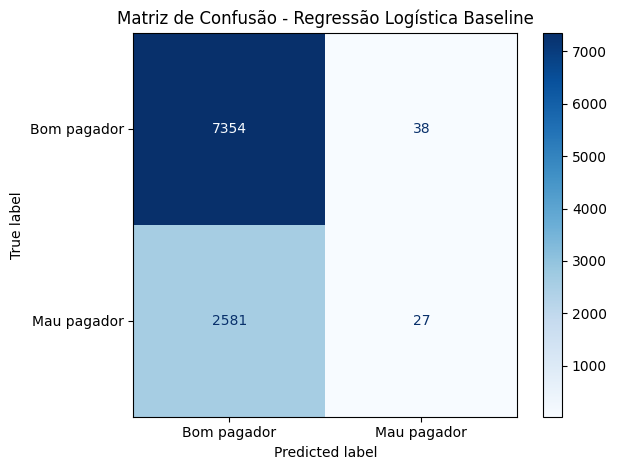

In [21]:

# AVALIAÇÃO DO MODELO BASELINE

# Avaliar o desempenho da Regressão Logística na previsão de inadimplência.

# Métricas:

# - Acurácia: proporção total de acertos;
# - Precisão: qualidade das previsões de inadimplência;
# - Recall: capacidade de identificar maus pagadores;
# - F1-score: equilíbrio entre precisão e recall;
# - Matriz de confusão: análise dos erros e acertos.


# Classe positiva:
# 1 = Mau pagador.

# A avaliação utiliza exclusivamente o conjunto de teste.


import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# 1. Previsões no conjunto de teste


y_pred_baseline = modelo_baseline.predict(
    X_test_baseline
)


# 2. Cálculo das métricas

resultados_baseline = pd.DataFrame({
    "Modelo": ["Regressão Logística - Baseline"],
    "Acurácia": [
        accuracy_score(y_test, y_pred_baseline)
    ],
    "Precisão": [
        precision_score(
            y_test, y_pred_baseline, zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            y_test, y_pred_baseline, zero_division=0
        )
    ],
    "F1-score": [
        f1_score(
            y_test, y_pred_baseline, zero_division=0
        )
    ]
})

print("MÉTRICAS DO MODELO BASELINE")

display(resultados_baseline.round(4))


# 3. Relatório detalhado de classificação


print("\nRELATÓRIO DE CLASSIFICAÇÃO")

print(
    classification_report(
        y_test,
        y_pred_baseline,
        target_names=["Bom pagador", "Mau pagador"],
        zero_division=0
    )
)


# 4. Matriz de confusão


matriz_baseline = confusion_matrix(
    y_test,
    y_pred_baseline,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_baseline,
    display_labels=["Bom pagador", "Mau pagador"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de Confusão - Regressão Logística Baseline")
plt.tight_layout()
plt.show()


ANÁLISE DA CAPACIDADE DISCRIMINATÓRIA
ROC-AUC: 0.6127
Average Precision: 0.3370
Prevalência de inadimplência: 0.2608

PROBABILIDADES POR CLASSE REAL


,count,mean,std,min,25%,50%,75%,max
Classe real,,,,,,,,
0,7392.00,0.25,0.09,0.05,0.19,0.25,0.31,0.73
1,2608.00,0.29,0.09,0.08,0.22,0.28,0.34,0.70


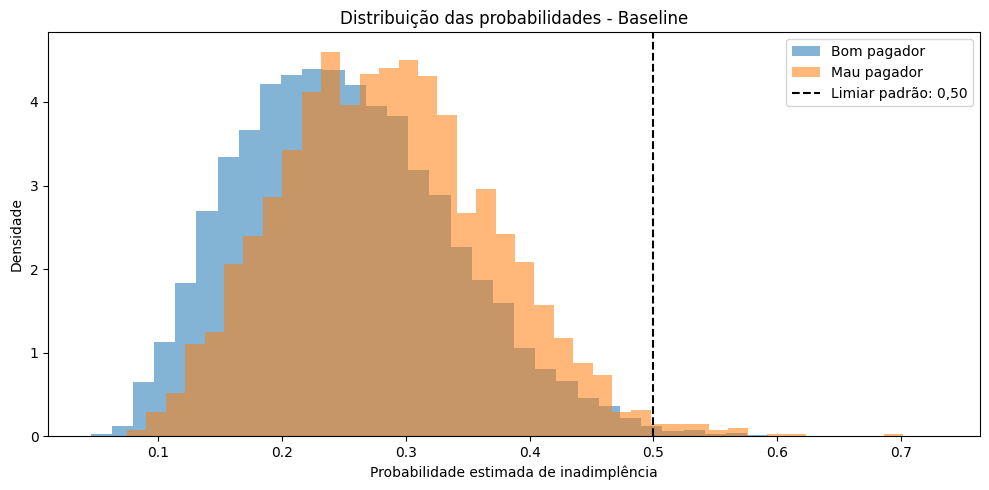

In [22]:


# ANÁLISE DAS PROBABILIDADES - MODELO BASELINE


# Investigar a distribuição das probabilidades previstase a capacidade do modelo de distinguir as classes.


# Nenhum novo modelo será treinado nesta etapa.


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)


# 1. Probabilidades previstas para inadimplência

# predict_proba retorna a probabilidade estimada
# para cada classe.
#
# A coluna correspondente à classe 1 representa
# a probabilidade estimada de inadimplência.

indice_classe_1 = list(
    modelo_baseline.classes_
).index(1)

probabilidades_baseline = (
    modelo_baseline.predict_proba(X_test_baseline)[
        :, indice_classe_1
    ]
)


# 2. Métricas independentes do limiar fixo de 0,50


roc_auc_baseline = roc_auc_score(
    y_test,
    probabilidades_baseline
)

ap_baseline = average_precision_score(
    y_test,
    probabilidades_baseline
)

print("ANÁLISE DA CAPACIDADE DISCRIMINATÓRIA")

print(f"ROC-AUC: {roc_auc_baseline:.4f}")
print(f"Average Precision: {ap_baseline:.4f}")

print(
    "Prevalência de inadimplência:",
    f"{y_test.mean():.4f}"
)

# 3. Distribuição das probabilidades por classe real


diagnostico_probabilidades = pd.DataFrame({
    "Classe real": np.asarray(y_test),
    "Probabilidade de inadimplência":
        probabilidades_baseline
})

print("\nPROBABILIDADES POR CLASSE REAL")

display(
    diagnostico_probabilidades.groupby(
        "Classe real"
    )["Probabilidade de inadimplência"].describe()
)


# 4. Visualização das probabilidades

plt.figure(figsize=(10, 5))

plt.hist(
    diagnostico_probabilidades.loc[
        diagnostico_probabilidades["Classe real"] == 0,
        "Probabilidade de inadimplência"
    ],
    bins=40,
    alpha=0.55,
    density=True,
    label="Bom pagador"
)

plt.hist(
    diagnostico_probabilidades.loc[
        diagnostico_probabilidades["Classe real"] == 1,
        "Probabilidade de inadimplência"
    ],
    bins=40,
    alpha=0.55,
    density=True,
    label="Mau pagador"
)

plt.axvline(
    0.50,
    color="black",
    linestyle="--",
    label="Limiar padrão: 0,50"
)

plt.xlabel("Probabilidade estimada de inadimplência")
plt.ylabel("Densidade")
plt.title(
    "Distribuição das probabilidades - Baseline"
)

plt.legend()
plt.tight_layout()
plt.show()


Calculando probabilidades por validação cruzada...
Validação cruzada concluída!

COMPARAÇÃO DOS LIMIARES


,Limiar,Acurácia,Precisão,Recall,F1-score
0,0.15,0.34,0.28,0.95,0.43
1,0.20,0.45,0.30,0.84,0.44
2,0.25,0.56,0.32,0.65,0.43
3,0.30,0.64,0.34,0.42,0.38
4,0.35,0.69,0.36,0.23,0.28
5,0.40,0.72,0.38,0.10,0.16
6,0.45,0.73,0.40,0.04,0.07
7,0.50,0.74,0.41,0.01,0.02



Melhor limiar entre os candidatos (F1-score): 0.2


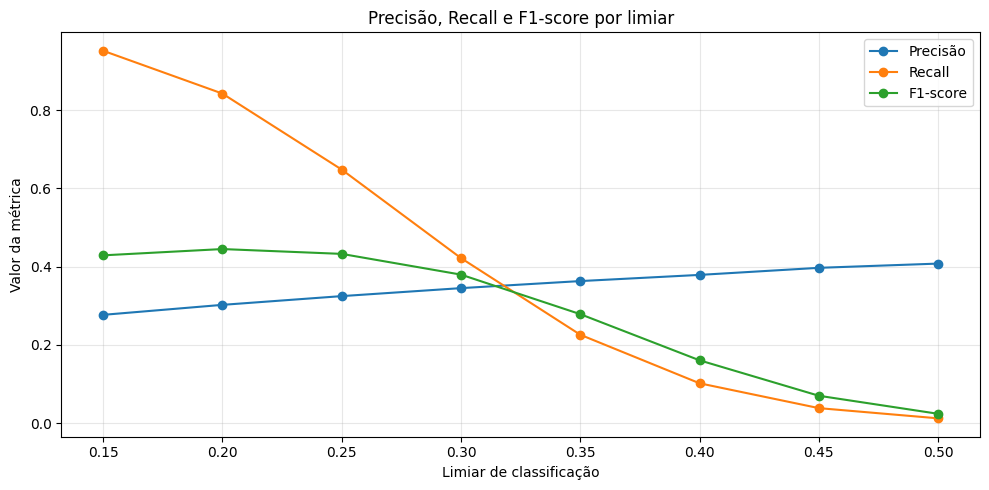

In [23]:

# ANÁLISE DE LIMIARES DE CLASSIFICAÇÃO

# Investigar como diferentes limiares afetam o desempenho da Regressão Logística na identificação de inadimplentes.

# Metodologia:
# - Validação cruzada estratificada com 5 divisões;
# - Previsões out-of-fold no conjunto de treinamento;
# - Comparação de precisão, recall e F1-score;
# - Preservação do conjunto de teste.

# O modelo baseline original permanece inalterado.


import numpy as np
import pandas as pd

from sklearn.base import clone

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# 1. Configuração da validação cruzada


validacao_cruzada = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. Probabilidades fora da amostra de treinamento



print("Calculando probabilidades por validação cruzada...")

probabilidades_cv = cross_val_predict(
    clone(modelo_baseline),
    X_train_baseline,
    y_train,
    cv=validacao_cruzada,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Validação cruzada concluída!")


# 3. Definição dos limiares candidatos

limiares = [
    0.15,
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50
]


# 4. Avaliação de cada limiar

resultados_limiares = []

for limiar in limiares:

    # Classifica como inadimplente quando a
    # probabilidade estimada é >= ao limiar.

    previsoes = (
        probabilidades_cv >= limiar
    ).astype(int)

    resultados_limiares.append({
        "Limiar": limiar,
        "Acurácia": accuracy_score(
            y_train, previsoes
        ),
        "Precisão": precision_score(
            y_train, previsoes,
            zero_division=0
        ),
        "Recall": recall_score(
            y_train, previsoes,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_train, previsoes,
            zero_division=0
        )
    })

# 5. Construção da tabela comparativa

tabela_limiares = pd.DataFrame(
    resultados_limiares
)

print("\nCOMPARAÇÃO DOS LIMIARES")

display(
    tabela_limiares.round(4)
)


# 6. Identificação do melhor F1-score


indice_melhor = (
    tabela_limiares["F1-score"].idxmax()
)

melhor_limiar_cv = float(
    tabela_limiares.loc[
        indice_melhor, "Limiar"
    ]
)

print(
    "\nMelhor limiar entre os candidatos (F1-score):",
    melhor_limiar_cv
)


# 7. Visualização das métricas por limiar

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for metrica in [
    "Precisão",
    "Recall",
    "F1-score"
]:
    plt.plot(
        tabela_limiares["Limiar"],
        tabela_limiares[metrica],
        marker="o",
        label=metrica
    )

plt.xlabel("Limiar de classificação")
plt.ylabel("Valor da métrica")
plt.title(
    "Precisão, Recall e F1-score por limiar"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:

# FEATURE ENGINEERING - EXPERIMENTO 1

# Criar novas características financeiras a partir de variáveis com distribuições assimétricas.

# Técnica: Transformação logarítmica log(1 + x).

# Variáveis:
# - RENDA_PESSOAL_MENSAL;
# - OUTRAS_RENDAS;
# - VALOR_PATRIMONIO_PESSOAL.

# Justificativa:
# Reduzir a influência de valores extremos e representar diferenças financeiras em uma escala comprimida.


import numpy as np


# 1. Cópias independentes dos dados


X_train_fe1 = X_train_baseline.copy()
X_test_fe1 = X_test_baseline.copy()


# 2. Definição das variáveis financeiras


variaveis_financeiras = [
    "RENDA_PESSOAL_MENSAL",
    "OUTRAS_RENDAS",
    "VALOR_PATRIMONIO_PESSOAL"
]


# 3. Criação das novas características

for coluna in variaveis_financeiras:

    nova_coluna = f"LOG_{coluna}"

    # clip(lower=0) impede valores negativos de serem enviados à transformação logarítmica.
    #
    # Valores ausentes continuam ausentes e serão tratados posteriormente pelo Pipeline.

    X_train_fe1[nova_coluna] = np.log1p(
        X_train_fe1[coluna].clip(lower=0)
    )

    X_test_fe1[nova_coluna] = np.log1p(
        X_test_fe1[coluna].clip(lower=0)
    )


# 4. Verificação das novas características

novas_variaveis_fe1 = [
    f"LOG_{coluna}"
    for coluna in variaveis_financeiras
]

print("NOVAS CARACTERÍSTICAS CRIADAS")

print(novas_variaveis_fe1)

print("\nDIMENSÕES DOS CONJUNTOS")

print("Treinamento:", X_train_fe1.shape)
print("Teste:", X_test_fe1.shape)

print("\nESTATÍSTICAS DAS NOVAS CARACTERÍSTICAS")

display(
    X_train_fe1[
        novas_variaveis_fe1
    ].describe().round(4)
)


NOVAS CARACTERÍSTICAS CRIADAS
['LOG_RENDA_PESSOAL_MENSAL', 'LOG_OUTRAS_RENDAS', 'LOG_VALOR_PATRIMONIO_PESSOAL']

DIMENSÕES DOS CONJUNTOS
Treinamento: (40000, 37)
Teste: (10000, 37)

ESTATÍSTICAS DAS NOVAS CARACTERÍSTICAS


,LOG_RENDA_PESSOAL_MENSAL,LOG_OUTRAS_RENDAS,LOG_VALOR_PATRIMONIO_PESSOAL
count,40000.00,40000.00,40000.00
mean,6.36,0.33,0.48
std,0.62,1.39,2.18
min,4.11,0.00,0.00
25%,5.89,0.00,0.00
50%,6.22,0.00,0.00
75%,6.69,0.00,0.00
max,13.77,12.18,15.61


In [25]:

# TREINAMENTO - EXPERIMENTO 1

# Avaliar o impacto das três características logarítmicas no desempenho da Regressão Logística.

# Estratégia:
# - Manter o mesmo conjunto de treinamento e teste;
# - Manter as mesmas variáveis categóricas;
# - Adicionar três novas características numéricas;
# - Manter os hiperparâmetros do classificador;
# - Reutilizar o pré-processamento do baseline.


from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Atualização da lista de variáveis numéricas


variaveis_num_fe1 = (
    variaveis_num + novas_variaveis_fe1
)

print("Variáveis numéricas:", len(variaveis_num_fe1))
print("Variáveis categóricas:", len(categoricas_baseline))


# 2. Construção do pré-processador


# Reutilizamos os pipelines numérico e categórico definidos no treinamento do baseline.


preprocessador_fe1 = ColumnTransformer(
    transformers=[
        (
            "numericas",
            clone(pipeline_numerico),
            variaveis_num_fe1
        ),
        (
            "categoricas",
            clone(pipeline_categorico),
            categoricas_baseline
        )
    ]
)


# 3. Construção do classificador

# Reutilizamos os mesmos parâmetros da Regressão
# Logística utilizada no modelo baseline.

modelo_fe1 = Pipeline(
    steps=[
        (
            "preprocessamento",
            preprocessador_fe1
        ),
        (
            "classificador",
            clone(
                modelo_baseline.named_steps[
                    "classificador"
                ]
            )
        )
    ]
)


# 4. Treinamento do modelo

print("\nIniciando treinamento do Experimento 1...")

modelo_fe1.fit(
    X_train_fe1,
    y_train
)

print("Treinamento concluído com sucesso!")


# 5. Verificação da dimensionalidade

X_train_fe1_transformado = (
    modelo_fe1
    .named_steps["preprocessamento"]
    .transform(X_train_fe1)
)

print("\nDIMENSÕES APÓS PRÉ-PROCESSAMENTO")

print(
    "Registros:",
    X_train_fe1_transformado.shape[0]
)

print(
    "Características:",
    X_train_fe1_transformado.shape[1]
)


Variáveis numéricas: 20
Variáveis categóricas: 17

Iniciando treinamento do Experimento 1...
Treinamento concluído com sucesso!

DIMENSÕES APÓS PRÉ-PROCESSAMENTO
Registros: 40000
Características: 195


COMPARAÇÃO DOS MODELOS


,Modelo,Acurácia,Precisão,Recall,F1-score,ROC-AUC,Average Precision
0,Baseline,0.74,0.42,0.01,0.02,0.61,0.34
1,Experimento 1 - Log,0.74,0.40,0.01,0.02,0.61,0.34



VARIAÇÃO DO EXPERIMENTO 1 EM RELAÇÃO AO BASELINE


,Diferença
Acurácia,-0.00
Precisão,-0.01
Recall,0.00
F1-score,-0.00
ROC-AUC,-0.00
Average Precision,-0.00


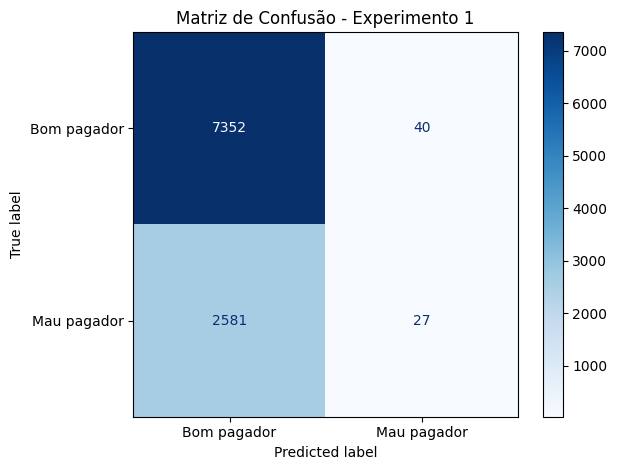

In [27]:

# AVALIAÇÃO COMPARATIVA - EXPERIMENTO 1

# Comparar o modelo baseline com o Experimento 1.

# Métricas:
# - Acurácia;
# - Precisão;
# - Recall;
# - F1-score;
# - ROC-AUC;
# - Average Precision.

# Ambos os modelos serão avaliados com limiar 0,50.


import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)


# 1. Previsões do Experimento 1


y_pred_fe1 = modelo_fe1.predict(
    X_test_fe1
)

probabilidades_fe1 = modelo_fe1.predict_proba(
    X_test_fe1
)[:, 1]


# 2. Função para calcular as métricas


def calcular_metricas(y_real, y_previsto, probabilidades):

    return {
        "Acurácia": accuracy_score(
            y_real, y_previsto
        ),
        "Precisão": precision_score(
            y_real, y_previsto,
            zero_division=0
        ),
        "Recall": recall_score(
            y_real, y_previsto,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_real, y_previsto,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_real, probabilidades
        ),
        "Average Precision": average_precision_score(
            y_real, probabilidades
        )
    }

# 3. Resultados do baseline


metricas_baseline = calcular_metricas(
    y_test,
    y_pred_baseline,
    probabilidades_baseline
)


# 4. Resultados do Experimento 1


metricas_fe1 = calcular_metricas(
    y_test,
    y_pred_fe1,
    probabilidades_fe1
)


# 5. Construção da tabela comparativa


comparacao_fe1 = pd.DataFrame(
    [
        {
            "Modelo": "Baseline",
            **metricas_baseline
        },
        {
            "Modelo": "Experimento 1 - Log",
            **metricas_fe1
        }
    ]
)

print("COMPARAÇÃO DOS MODELOS")

display(
    comparacao_fe1.round(4)
)


# 6. Diferença entre as métricas

colunas_metricas = [
    "Acurácia",
    "Precisão",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "Average Precision"
]

diferencas_fe1 = (
    comparacao_fe1.loc[1, colunas_metricas]
    - comparacao_fe1.loc[0, colunas_metricas]
)

print("\nVARIAÇÃO DO EXPERIMENTO 1 EM RELAÇÃO AO BASELINE")

display(
    diferencas_fe1.to_frame(
        name="Diferença"
    ).round(4)
)


# 7. Matriz de confusão do Experimento 1


from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matriz_fe1 = confusion_matrix(
    y_test,
    y_pred_fe1,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_fe1,
    display_labels=[
        "Bom pagador",
        "Mau pagador"
    ]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Matriz de Confusão - Experimento 1"
)

plt.tight_layout()
plt.show()


In [28]:

# FEATURE ENGINEERING - EXPERIMENTO 2

# Criar características financeiras com significado interpretável para a análise de risco de crédito.

# Novas características:
# 1. POSSUI_OUTRAS_RENDAS
# 2. POSSUI_PATRIMONIO
# 3. RENDA_TOTAL_DECLARADA
# 4. TOTAL_CONTAS_BANCARIAS

# Estratégia:
# - Partir dos dados originais do baseline;
# - Preservar as variáveis existentes;
# - Criar quatro novas características;
# - Manter a mesma divisão treino/teste.


import numpy as np
import pandas as pd


# 1. Cópias independentes dos conjuntos baseline

X_train_fe2 = X_train_baseline.copy()
X_test_fe2 = X_test_baseline.copy()


# 2. Função de criação das características


def criar_caracteristicas_financeiras(X):

    # Preserva os dados recebidos.
    X = X.copy()


    # 2.1. Indicador de outras fontes de renda


    # 1 = Cliente declarou outras rendas positivas.
    # 0 = Cliente não declarou outras rendas positivas.

    # Valores ausentes permanecem como NaN.

    X["POSSUI_OUTRAS_RENDAS"] = (
        X["OUTRAS_RENDAS"]
        .gt(0)
        .astype(float)
    )

    X.loc[
        X["OUTRAS_RENDAS"].isna(),
        "POSSUI_OUTRAS_RENDAS"
    ] = np.nan


    # 2.2. Indicador de patrimônio

    # 1 = Cliente declarou patrimônio positivo.
    # 0 = Cliente não declarou patrimônio positivo.

    X["POSSUI_PATRIMONIO"] = (
        X["VALOR_PATRIMONIO_PESSOAL"]
        .gt(0)
        .astype(float)
    )

    X.loc[
        X["VALOR_PATRIMONIO_PESSOAL"].isna(),
        "POSSUI_PATRIMONIO"
    ] = np.nan


    # 2.3. Renda total declarada

    # Soma da renda pessoal mensal com outras rendas.
    # min_count=2 exige que os dois componentes estejam presentes para calcular o total.

    X["RENDA_TOTAL_DECLARADA"] = (
        X[
            [
                "RENDA_PESSOAL_MENSAL",
                "OUTRAS_RENDAS"
            ]
        ]
        .sum(axis=1, min_count=2)
    )


    # 2.4. Total de contas bancárias



    X["TOTAL_CONTAS_BANCARIAS"] = (
        X[
            [
                "QUANT_CONTAS_BANCARIAS",
                "QUANT_CONTAS_BANCARIAS_ESPECIAIS"
            ]
        ]
        .sum(axis=1, min_count=2)
    )

    return X


# 3. Aplicação das transformações


X_train_fe2 = criar_caracteristicas_financeiras(
    X_train_fe2
)

X_test_fe2 = criar_caracteristicas_financeiras(
    X_test_fe2
)


# 4. Identificação das novas características


novas_variaveis_fe2 = [
    "POSSUI_OUTRAS_RENDAS",
    "POSSUI_PATRIMONIO",
    "RENDA_TOTAL_DECLARADA",
    "TOTAL_CONTAS_BANCARIAS"
]


# 5. Verificação dos resultados


print("NOVAS CARACTERÍSTICAS CRIADAS")

print(novas_variaveis_fe2)

print("\nDIMENSÕES DOS CONJUNTOS")

print("Treinamento:", X_train_fe2.shape)
print("Teste:", X_test_fe2.shape)

print("\nESTATÍSTICAS DESCRITIVAS")

display(
    X_train_fe2[
        novas_variaveis_fe2
    ].describe().round(4)
)

print("\nVALORES AUSENTES")

display(
    X_train_fe2[
        novas_variaveis_fe2
    ].isna().sum()
)


NOVAS CARACTERÍSTICAS CRIADAS
['POSSUI_OUTRAS_RENDAS', 'POSSUI_PATRIMONIO', 'RENDA_TOTAL_DECLARADA', 'TOTAL_CONTAS_BANCARIAS']

DIMENSÕES DOS CONJUNTOS
Treinamento: (40000, 38)
Teste: (10000, 38)

ESTATÍSTICAS DESCRITIVAS


,POSSUI_OUTRAS_RENDAS,POSSUI_PATRIMONIO,RENDA_TOTAL_DECLARADA,TOTAL_CONTAS_BANCARIAS
count,40000.00,40000.00,40000.00,40000.00
mean,0.06,0.05,920.30,0.71
std,0.23,0.21,7920.92,0.96
min,0.00,0.00,60.00,0.00
25%,0.00,0.00,372.00,0.00
50%,0.00,0.00,515.00,0.00
75%,0.00,0.00,839.00,2.00
max,1.00,1.00,959000.00,4.00



VALORES AUSENTES


,0
POSSUI_OUTRAS_RENDAS,0
POSSUI_PATRIMONIO,0
RENDA_TOTAL_DECLARADA,0
TOTAL_CONTAS_BANCARIAS,0


In [29]:


# REVISÃO DAS CARACTERÍSTICAS - EXPERIMENTO 2

# Garantir que as características criadas tenham interpretações compatíveis com o dicionário de dados.

# Decisão:
# Remover TOTAL_CONTAS_BANCARIAS, pois o dicionário não confirma que os dois campos originais possam ser somados diretamente.




# 1. Remoção da característica não validada


X_train_fe2 = X_train_fe2.drop(
    columns=["TOTAL_CONTAS_BANCARIAS"]
)

X_test_fe2 = X_test_fe2.drop(
    columns=["TOTAL_CONTAS_BANCARIAS"]
)


# 2. Atualização da lista de novas características

novas_variaveis_fe2 = [
    "POSSUI_OUTRAS_RENDAS",
    "POSSUI_PATRIMONIO",
    "RENDA_TOTAL_DECLARADA"
]


# 3. Verificação da estrutura final


print("CARACTERÍSTICAS VALIDADAS")

print(novas_variaveis_fe2)

print("\nDIMENSÕES DOS CONJUNTOS")

print("Treinamento:", X_train_fe2.shape)
print("Teste:", X_test_fe2.shape)

print("\nESTATÍSTICAS DESCRITIVAS")

display(
    X_train_fe2[
        novas_variaveis_fe2
    ].describe().round(4)
)


# 4. Verificação de consistência


assert X_train_fe2.shape[1] == 37
assert X_test_fe2.shape[1] == 37

assert list(X_train_fe2.columns) == list(X_test_fe2.columns)

print("\nValidação concluída com sucesso!")


CARACTERÍSTICAS VALIDADAS
['POSSUI_OUTRAS_RENDAS', 'POSSUI_PATRIMONIO', 'RENDA_TOTAL_DECLARADA']

DIMENSÕES DOS CONJUNTOS
Treinamento: (40000, 37)
Teste: (10000, 37)

ESTATÍSTICAS DESCRITIVAS


,POSSUI_OUTRAS_RENDAS,POSSUI_PATRIMONIO,RENDA_TOTAL_DECLARADA
count,40000.00,40000.00,40000.00
mean,0.06,0.05,920.30
std,0.23,0.21,7920.92
min,0.00,0.00,60.00
25%,0.00,0.00,372.00
50%,0.00,0.00,515.00
75%,0.00,0.00,839.00
max,1.00,1.00,959000.00



Validação concluída com sucesso!


In [30]:


# TREINAMENTO - EXPERIMENTO 2

# Treinar uma Regressão Logística utilizando três características financeiras derivadas.
#
# Estratégia:

# - Manter o algoritmo do baseline;
# - Manter os mesmos hiperparâmetros;
# - Preservar a divisão treino/teste;
# - Incluir somente as três novas variáveis;
# - Evitar alterações no modelo baseline original.


from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


# 1. Atualização das variáveis numéricas


variaveis_num_fe2 = (
    variaveis_num + novas_variaveis_fe2
)

print("Variáveis numéricas:", len(variaveis_num_fe2))
print("Variáveis categóricas:", len(categoricas_baseline))


# 2. Construção do pré-processador


preprocessador_fe2 = ColumnTransformer(
    transformers=[
        (
            "numericas",
            clone(pipeline_numerico),
            variaveis_num_fe2
        ),
        (
            "categoricas",
            clone(pipeline_categorico),
            categoricas_baseline
        )
    ]
)


# 3. Construção do modelo

modelo_fe2 = Pipeline(
    steps=[
        (
            "preprocessamento",
            preprocessador_fe2
        ),
        (
            "classificador",
            clone(
                modelo_baseline.named_steps[
                    "classificador"
                ]
            )
        )
    ]
)


# 4. Treinamento


print("\nIniciando treinamento do Experimento 2...")

modelo_fe2.fit(
    X_train_fe2,
    y_train
)

print("Treinamento concluído com sucesso!")


# 5. Verificação da dimensionalidade

X_train_fe2_transformado = (
    modelo_fe2
    .named_steps["preprocessamento"]
    .transform(X_train_fe2)
)

print("\nDIMENSÕES APÓS PRÉ-PROCESSAMENTO")

print(
    "Registros:",
    X_train_fe2_transformado.shape[0]
)

print(
    "Características:",
    X_train_fe2_transformado.shape[1]
)


Variáveis numéricas: 20
Variáveis categóricas: 17

Iniciando treinamento do Experimento 2...
Treinamento concluído com sucesso!

DIMENSÕES APÓS PRÉ-PROCESSAMENTO
Registros: 40000
Características: 195


In [31]:

# VALIDAÇÃO CRUZADA - BASELINE VS EXPERIMENTO 2

# Verificar se as características financeiras derivadas melhoram a capacidade preditiva do classificador.
#
# Metodologia:

# - StratifiedKFold com 5 divisões;
# - Mesmas divisões para os dois modelos;
# - Pré-processamento ajustado dentro de cada fold;
# - Comparação de métricas de classificação.


import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)


# 1. Configuração da validação cruzada


cv_fe2 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# 2. Métricas de avaliação

metricas_cv = {
    "ROC-AUC": "roc_auc",
    "Average Precision": "average_precision",
    "Recall": "recall",
    "F1-score": "f1"
}


# 3. Validação cruzada do baseline

print("Avaliando modelo baseline...")

cv_baseline = cross_validate(
    clone(modelo_baseline),
    X_train_baseline,
    y_train,
    cv=cv_fe2,
    scoring=metricas_cv,
    n_jobs=-1
)


# 4. Validação cruzada do Experimento 2

print("Avaliando Experimento 2...")

cv_experimento2 = cross_validate(
    clone(modelo_fe2),
    X_train_fe2,
    y_train,
    cv=cv_fe2,
    scoring=metricas_cv,
    n_jobs=-1
)


# 5. Construção da tabela comparativa


resultados_cv_fe2 = []

for nome, resultados in [
    ("Baseline", cv_baseline),
    ("Experimento 2 - Financeiro", cv_experimento2)
]:

    linha = {"Modelo": nome}

    for metrica in metricas_cv:

        valores = resultados[
            f"test_{metrica}"
        ]

        linha[f"{metrica} - Média"] = valores.mean()
        linha[f"{metrica} - Desvio"] = valores.std()

    resultados_cv_fe2.append(linha)

tabela_cv_fe2 = pd.DataFrame(
    resultados_cv_fe2
)

print("\nCOMPARAÇÃO POR VALIDAÇÃO CRUZADA")

display(
    tabela_cv_fe2.round(4)
)


# 6. Diferenças das métricas principais

diferenca_roc = (
    tabela_cv_fe2.loc[1, "ROC-AUC - Média"]
    - tabela_cv_fe2.loc[0, "ROC-AUC - Média"]
)

diferenca_ap = (
    tabela_cv_fe2.loc[1, "Average Precision - Média"]
    - tabela_cv_fe2.loc[0, "Average Precision - Média"]
)

print("\nVARIAÇÃO EM RELAÇÃO AO BASELINE")

print(f"Diferença ROC-AUC: {diferenca_roc:+.4f}")
print(f"Diferença Average Precision: {diferenca_ap:+.4f}")


Avaliando modelo baseline...
Avaliando Experimento 2...

COMPARAÇÃO POR VALIDAÇÃO CRUZADA


,Modelo,ROC-AUC - Média,ROC-AUC - Desvio,Average Precision - Média,Average Precision - Desvio,Recall - Média,Recall - Desvio,F1-score - Média,F1-score - Desvio
0,Baseline,0.62,0.01,0.34,0.01,0.01,0.00,0.02,0.00
1,Experimento 2 - Financeiro,0.62,0.01,0.34,0.01,0.01,0.00,0.02,0.00



VARIAÇÃO EM RELAÇÃO AO BASELINE
Diferença ROC-AUC: -0.0001
Diferença Average Precision: -0.0002


In [32]:


# TREINAMENTO DO RANDOM FOREST

# Construir um segundo algoritmo de classificação para o problema de inadimplência da QuantumFinance.

# Estratégia:

# - Utilizar as mesmas 34 variáveis do baseline;
# - Manter a mesma divisão treino/teste;
# - Reutilizar o tratamento de valores ausentes;
# - Reutilizar o One-Hot Encoding;
# - Treinar um Random Forest com 100 árvores.


from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier


# 1. Construção do classificador

# n_estimators=100: Número de árvores de decisão utilizadas.
# random_state=42: Garante reprodutibilidade.

# n_jobs=-1: Utiliza os núcleos disponíveis do processador.

classificador_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)


# 2. Construção do Pipeline

# Reutilizamos o pré-processador do baseline.

# clone cria uma cópia independente, que será ajustada novamente com os dados de treinamento.

modelo_rf = Pipeline(
    steps=[
        (
            "preprocessamento",
            clone(preprocessador_baseline)
        ),
        (
            "classificador",
            classificador_rf
        )
    ]
)


# 3. Treinamento do Random Forest


print("Iniciando treinamento do Random Forest...")

modelo_rf.fit(
    X_train_baseline,
    y_train
)

print("Treinamento concluído com sucesso!")


# 4. Verificação da estrutura


X_train_rf_transformado = (
    modelo_rf
    .named_steps["preprocessamento"]
    .transform(X_train_baseline)
)

print("\nDIMENSÕES APÓS PRÉ-PROCESSAMENTO")

print(
    "Registros:",
    X_train_rf_transformado.shape[0]
)

print(
    "Características:",
    X_train_rf_transformado.shape[1]
)

print("\nQUANTIDADE DE ÁRVORES")

print(
    modelo_rf.named_steps[
        "classificador"
    ].n_estimators
)


Iniciando treinamento do Random Forest...
Treinamento concluído com sucesso!

DIMENSÕES APÓS PRÉ-PROCESSAMENTO
Registros: 40000
Características: 192

QUANTIDADE DE ÁRVORES
100


In [33]:

# COMPARAÇÃO DE ALGORITMOS - VALIDAÇÃO CRUZADA

# Comparar a capacidade preditiva da Regressão Logística e do Random Forest para classificação de inadimplência.

# Metodologia:
# - Mesmas 34 variáveis explicativas;
# - Mesmo conjunto de treinamento;
# - Validação cruzada estratificada com 5 divisões;
# - Mesmas divisões para os dois algoritmos;
# - Pré-processamento ajustado dentro de cada fold.

# Métricas:
# - ROC-AUC;
# - Average Precision;
# - Acurácia;
# - Precisão;
# - Recall;
# - F1-score.


import numpy as np
import pandas as pd

from sklearn.base import clone

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)


# 1. Configuração da validação cruzada


cv_algoritmos = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# 2. Definição das métricas


metricas_algoritmos = {
    "ROC-AUC": "roc_auc",
    "Average Precision": "average_precision",
    "Acurácia": "accuracy",
    "Precisão": "precision",
    "Recall": "recall",
    "F1-score": "f1"
}


# 3. Organização dos modelos


modelos_comparacao = {
    "Regressão Logística": modelo_baseline,
    "Random Forest": modelo_rf
}


# 4. Avaliação por validação cruzada


resultados_algoritmos = []

resultados_folds_algoritmos = {}

for nome_modelo, modelo in modelos_comparacao.items():

    print(f"\nAvaliando: {nome_modelo}")



    resultados_cv = cross_validate(
        clone(modelo),
        X_train_baseline,
        y_train,
        cv=cv_algoritmos,
        scoring=metricas_algoritmos,
        n_jobs=1
    )

    # Preserva os resultados individuais dos folds.
    resultados_folds_algoritmos[nome_modelo] = resultados_cv

    linha = {
        "Modelo": nome_modelo
    }

    # Calcula a média e o desvio-padrão de cada métrica nos cinco folds.

    for metrica in metricas_algoritmos:

        valores = resultados_cv[
            f"test_{metrica}"
        ]

        linha[f"{metrica} - Média"] = valores.mean()

        linha[f"{metrica} - Desvio"] = valores.std()

    resultados_algoritmos.append(linha)


# 5. Construção da tabela comparativa


tabela_algoritmos = pd.DataFrame(
    resultados_algoritmos
)

print("\nCOMPARAÇÃO DOS ALGORITMOS")

display(
    tabela_algoritmos.round(4)
)


# 6. Diferença entre Random Forest e Regressão Logística


print("\nDIFERENÇAS: RANDOM FOREST - REGRESSÃO LOGÍSTICA")

diferencas_algoritmos = {}

for metrica in metricas_algoritmos:

    coluna = f"{metrica} - Média"

    diferencas_algoritmos[metrica] = (
        tabela_algoritmos.loc[1, coluna]
        - tabela_algoritmos.loc[0, coluna]
    )

display(
    pd.DataFrame(
        diferencas_algoritmos.items(),
        columns=["Métrica", "Diferença"]
    ).round(4)
)



Avaliando: Regressão Logística

Avaliando: Random Forest

COMPARAÇÃO DOS ALGORITMOS


,Modelo,ROC-AUC - Média,ROC-AUC - Desvio,Average Precision - Média,Average Precision - Desvio,Acurácia - Média,Acurácia - Desvio,Precisão - Média,Precisão - Desvio,Recall - Média,Recall - Desvio,F1-score - Média,F1-score - Desvio
0,Regressão Logística,0.62,0.01,0.34,0.01,0.74,0.00,0.41,0.05,0.01,0.00,0.02,0.00
1,Random Forest,0.61,0.01,0.34,0.01,0.74,0.00,0.43,0.02,0.04,0.00,0.08,0.00



DIFERENÇAS: RANDOM FOREST - REGRESSÃO LOGÍSTICA


,Métrica,Diferença
0,ROC-AUC,-0.01
1,Average Precision,-0.00
2,Acurácia,-0.00
3,Precisão,0.02
4,Recall,0.03
5,F1-score,0.06


### Resultados da comparação entre algoritmos

A comparação entre Regressão Logística e Random Forest foi realizada utilizando as mesmas 34 variáveis explicativas, a mesma divisão original dos dados e validação cruzada estratificada com cinco divisões.

Os resultados demonstraram que o Random Forest apresentou maior recall e F1-score com o limiar padrão de classificação de 0,50.

O recall médio aumentou de aproximadamente 1% para 4%, enquanto o F1-score passou de aproximadamente 0,02 para 0,08.

Entretanto, a ROC-AUC média do Random Forest foi ligeiramente inferior à da Regressão Logística, passando de aproximadamente 0,62 para 0,61.

A Average Precision permaneceu próxima de 0,34 nos dois modelos.

Esses resultados indicam que o Random Forest conseguiu identificar uma proporção maior de inadimplentes com o limiar padrão, mas não demonstrou melhoria na capacidade discriminatória geral.

**Conclusão:** a utilização de um algoritmo capaz de capturar relações não lineares não foi suficiente para produzir uma melhoria consistente nas métricas de discriminação.

A comparação também evidencia que diferentes algoritmos podem apresentar comportamentos distintos em um mesmo limiar de classificação.

Dessa forma, os próximos experimentos deverão investigar estratégias adicionais de Feature Engineering, especialmente o tratamento das variáveis categóricas de alta cardinalidade e a seleção de características relevantes.

In [34]:


# FEATURE ENGINEERING - CATEGORIAS DE ALTA CARDINALIDADE

# Investigar a distribuição de frequência das categorias presentes nas nove variáveis de alta cardinalidade.
#
# Queremos identificar:

# - Quantidade total de categorias;
# - Quantidade de categorias com menos de 10 registros;
# - Quantidade de categorias com menos de 50 registros;
# - Percentual de registros pertencentes a categorias raras.


import pandas as pd


# 1. Lista das variáveis de alta cardinalidade


variaveis_alta = categoricas_alta.copy()


# 2. Análise da frequência das categorias


resultados_categorias_raras = []

for coluna in variaveis_alta:

    # Conta as ocorrências de cada categoria.

    # dropna=False inclui valores ausentes como uma categoria para fins de diagnóstico.

    frequencias = X_train[
        coluna
    ].value_counts(dropna=False)

    # Identifica categorias com baixa frequência.

    categorias_menos_10 = frequencias[
        frequencias < 10
    ]

    categorias_menos_50 = frequencias[
        frequencias < 50
    ]

    # Calcula a proporção de registros pertencentes às categorias com menos de 10 ocorrências.

    percentual_registros_raros = (
        categorias_menos_10.sum()
        / len(X_train)
        * 100
    )

    resultados_categorias_raras.append({
        "Variável": coluna,
        "Total categorias": len(frequencias),
        "Categorias < 10": len(categorias_menos_10),
        "Categorias < 50": len(categorias_menos_50),
        "% registros categorias < 10":
            percentual_registros_raros
    })


# 3. Construção da tabela

tabela_categorias_raras = pd.DataFrame(
    resultados_categorias_raras
)

# Organiza da maior para a menor cardinalidade.

tabela_categorias_raras = (
    tabela_categorias_raras.sort_values(
        "Total categorias",
        ascending=False
    )
)


# 4. Apresentação dos resultados


print("DIAGNÓSTICO DAS CATEGORIAS RARAS")

display(
    tabela_categorias_raras.round(2)
)


DIAGNÓSTICO DAS CATEGORIAS RARAS


,Variável,Total categorias,Categorias < 10,Categorias < 50,% registros categorias < 10
0,BAIRRO_RESIDENCIAL,12550,11895,12504,53.93
1,CIDADE_NASCIMENTO,8726,8003,8645,38.94
2,BAIRRO_PROFISSIONAL,4337,4252,4327,16.93
3,CIDADE_RESIDENCIAL,3205,2471,3035,14.27
4,CIDADE_PROFISSIONAL,2009,1750,1965,9.96
5,CEP_PROFISSIONAL_3,785,245,557,2.25
6,CEP_RESIDENCIAL_3,785,245,557,2.25
7,CODIGO_AREA_TELEFONE_RESIDENCIAL,94,26,30,0.09
8,CODIGO_AREA_TELEFONE_PROFISSIONAL,82,20,35,0.15


In [35]:

# EXPERIMENTO 3 - AGRUPAMENTO DE CATEGORIAS RARAS

# Recuperar as nove variáveis categóricas de alta cardinalidade anteriormente excluídas do baseline.

# Técnica: One-Hot Encoding com agrupamento de categorias raras.


import numpy as np

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer


# 1. Seleção das variáveis


variaveis_num_fe3 = variaveis_num.copy()

variaveis_cat_fe3 = (
    categoricas_baseline + categoricas_alta
)

colunas_fe3 = (
    variaveis_num_fe3 + variaveis_cat_fe3
)

X_train_fe3 = X_train[
    colunas_fe3
].copy()

X_test_fe3 = X_test[
    colunas_fe3
].copy()

print("DIMENSÕES ORIGINAIS")

print("Treinamento:", X_train_fe3.shape)
print("Teste:", X_test_fe3.shape)

print("\nTIPOS DE VARIÁVEIS")

print("Numéricas:", len(variaveis_num_fe3))
print("Categóricas:", len(variaveis_cat_fe3))


# 2. Pipeline categórico


pipeline_categorico_fe3 = Pipeline(
    steps=[
        (
            "conversao",
            FunctionTransformer(
                converter_categoricas,
                validate=False
            )
        ),
        (
            "imputacao",
            SimpleImputer(
                strategy="constant",
                fill_value="AUSENTE"
            )
        ),
        (
            "codificacao",
            OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                min_frequency=10,
                max_categories=50,
                sparse_output=True
            )
        )
    ]
)


# 3. Pré-processador completo


preprocessador_fe3 = ColumnTransformer(
    transformers=[
        (
            "numericas",
            clone(pipeline_numerico),
            variaveis_num_fe3
        ),
        (
            "categoricas",
            pipeline_categorico_fe3,
            variaveis_cat_fe3
        )
    ]
)


# 4. Construção do modelo


modelo_fe3 = Pipeline(
    steps=[
        (
            "preprocessamento",
            preprocessador_fe3
        ),
        (
            "classificador",
            clone(
                modelo_baseline.named_steps[
                    "classificador"
                ]
            )
        )
    ]
)


# 5. Treinamento

print("\nTreinando Experimento 3...")

modelo_fe3.fit(
    X_train_fe3,
    y_train
)

print("Treinamento concluído com sucesso!")


# 6. Verificação da dimensionalidade


X_train_fe3_transformado = (
    modelo_fe3
    .named_steps["preprocessamento"]
    .transform(X_train_fe3)
)

print("\nDIMENSÕES APÓS PRÉ-PROCESSAMENTO")

print(
    "Registros:",
    X_train_fe3_transformado.shape[0]
)

print(
    "Características:",
    X_train_fe3_transformado.shape[1]
)

print("\nCOMPARAÇÃO COM O BASELINE")

print("Baseline: 192 características")

print(
    "Experimento 3:",
    X_train_fe3_transformado.shape[1],
    "características"
)


DIMENSÕES ORIGINAIS
Treinamento: (40000, 43)
Teste: (10000, 43)

TIPOS DE VARIÁVEIS
Numéricas: 17
Categóricas: 26

Treinando Experimento 3...
Treinamento concluído com sucesso!

DIMENSÕES APÓS PRÉ-PROCESSAMENTO
Registros: 40000
Características: 633

COMPARAÇÃO COM O BASELINE
Baseline: 192 características
Experimento 3: 633 características


In [36]:

# EXPERIMENTO 3 - AVALIAÇÃO POR VALIDAÇÃO CRUZADA


# Comparar o baseline com o Experimento 3.

# Baseline:
# - 34 variáveis originais;
# - One-Hot Encoding convencional;
# - 192 características após pré-processamento.

# Experimento 3:
# - 43 variáveis originais;
# - Agrupamento de categorias raras;
# - 633 características no treinamento completo.



import pandas as pd
import numpy as np

from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)


# 1. Configuração da validação cruzada


cv_fe3 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# 2. Métricas de avaliação

metricas_fe3 = {
    "ROC-AUC": "roc_auc",
    "Average Precision": "average_precision",
    "Acurácia": "accuracy",
    "Precisão": "precision",
    "Recall": "recall",
    "F1-score": "f1"
}


# 3. Avaliação do baseline


print("Avaliando baseline...")

cv_baseline_fe3 = cross_validate(
    clone(modelo_baseline),
    X_train_baseline,
    y_train,
    cv=cv_fe3,
    scoring=metricas_fe3,
    n_jobs=-1
)


# 4. Avaliação do Experimento 3


print("Avaliando Experimento 3...")

cv_modelo_fe3 = cross_validate(
    clone(modelo_fe3),
    X_train_fe3,
    y_train,
    cv=cv_fe3,
    scoring=metricas_fe3,
    n_jobs=-1
)


# 5. Construção da tabela comparativa


resultados_comparacao_fe3 = []

for nome, resultados in [
    ("Baseline", cv_baseline_fe3),
    ("Experimento 3 - Categorias raras", cv_modelo_fe3)
]:

    linha = {"Modelo": nome}

    for metrica in metricas_fe3:

        valores = resultados[
            f"test_{metrica}"
        ]

        linha[f"{metrica} - Média"] = valores.mean()
        linha[f"{metrica} - Desvio"] = valores.std()

    resultados_comparacao_fe3.append(linha)

tabela_comparacao_fe3 = pd.DataFrame(
    resultados_comparacao_fe3
)

print("\nCOMPARAÇÃO BASELINE VS EXPERIMENTO 3")

display(
    tabela_comparacao_fe3.round(4)
)


# 6. Cálculo das diferenças


diferencas_fe3 = []

for metrica in metricas_fe3:

    coluna = f"{metrica} - Média"

    diferenca = (
        tabela_comparacao_fe3.loc[1, coluna]
        - tabela_comparacao_fe3.loc[0, coluna]
    )

    diferencas_fe3.append({
        "Métrica": metrica,
        "Diferença": diferenca
    })

tabela_diferencas_fe3 = pd.DataFrame(
    diferencas_fe3
)

print("\nDIFERENÇAS: EXPERIMENTO 3 - BASELINE")

display(
    tabela_diferencas_fe3.round(4)
)


Avaliando baseline...
Avaliando Experimento 3...

COMPARAÇÃO BASELINE VS EXPERIMENTO 3


,Modelo,ROC-AUC - Média,ROC-AUC - Desvio,Average Precision - Média,Average Precision - Desvio,Acurácia - Média,Acurácia - Desvio,Precisão - Média,Precisão - Desvio,Recall - Média,Recall - Desvio,F1-score - Média,F1-score - Desvio
0,Baseline,0.62,0.01,0.34,0.01,0.74,0.00,0.41,0.05,0.01,0.00,0.02,0.00
1,Experimento 3 - Categorias raras,0.64,0.01,0.36,0.01,0.74,0.00,0.44,0.04,0.05,0.01,0.09,0.01



DIFERENÇAS: EXPERIMENTO 3 - BASELINE


,Métrica,Diferença
0,ROC-AUC,0.02
1,Average Precision,0.02
2,Acurácia,-0.00
3,Precisão,0.04
4,Recall,0.04
5,F1-score,0.07


AVALIAÇÃO FINAL - CONJUNTO DE TESTE


,Métrica,Resultado
0,Acurácia,0.74
1,Precisão,0.45
2,Recall,0.05
3,F1-score,0.09
4,ROC-AUC,0.63
5,Average Precision,0.36



MATRIZ DE CONFUSÃO
[[7231  161]
 [2475  133]]


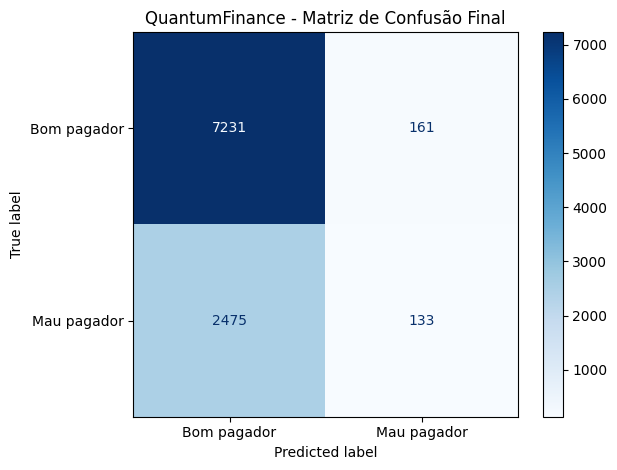


DETALHAMENTO
Verdadeiros negativos: 7231
Falsos positivos: 161
Falsos negativos: 2475
Verdadeiros positivos: 133

Avaliação final concluída!


In [37]:


# AVALIAÇÃO FINAL - EXPERIMENTO 3


# Modelo selecionado: Regressão Logística com agrupamento de categorias raras.

# Avaliar o desempenho no conjunto de teste reservado.


import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# 1. Previsões no conjunto de teste


y_pred_final = modelo_fe3.predict(X_test_fe3)

y_prob_final = modelo_fe3.predict_proba(
    X_test_fe3
)[:, 1]


# 2. Cálculo das métricas


metricas_finais = {
    "Acurácia": accuracy_score(
        y_test, y_pred_final
    ),
    "Precisão": precision_score(
        y_test, y_pred_final,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_final
    ),
    "F1-score": f1_score(
        y_test, y_pred_final
    ),
    "ROC-AUC": roc_auc_score(
        y_test, y_prob_final
    ),
    "Average Precision": average_precision_score(
        y_test, y_prob_final
    )
}

tabela_metricas_finais = pd.DataFrame(
    metricas_finais.items(),
    columns=["Métrica", "Resultado"]
)

print("AVALIAÇÃO FINAL - CONJUNTO DE TESTE")

display(
    tabela_metricas_finais.round(4)
)


# 3. Matriz de confusão


matriz_final = confusion_matrix(
    y_test,
    y_pred_final,
    labels=[0, 1]
)

print("\nMATRIZ DE CONFUSÃO")

print(matriz_final)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_final,
    display_labels=[
        "Bom pagador",
        "Mau pagador"
    ]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "QuantumFinance - Matriz de Confusão Final"
)

plt.tight_layout()
plt.show()


# 4. Detalhamento da matriz


tn, fp, fn, tp = matriz_final.ravel()

print("\nDETALHAMENTO")

print("Verdadeiros negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdadeiros positivos:", tp)

print("\nAvaliação final concluída!")


## Conclusão do projeto — QuantumFinance

O projeto teve como objetivo aplicar técnicas de Feature Engineering para investigar melhorias na previsão de inadimplência de clientes de cartão de crédito.

Foram analisados 50.000 registros, utilizando 80% dos dados para treinamento e 20% para teste, com divisão estratificada pela variável-alvo.

Inicialmente, foi desenvolvido um modelo baseline utilizando Regressão Logística. Em seguida, foram avaliadas três estratégias de Feature Engineering:

1. Transformações logarítmicas de variáveis financeiras.
2. Criação de características financeiras derivadas.
3. Recuperação de variáveis categóricas de alta cardinalidade com agrupamento de categorias raras.

Também foi realizada uma comparação entre Regressão Logística e Random Forest.

Os dois primeiros experimentos de Feature Engineering não apresentaram melhorias relevantes. O Random Forest também não superou a Regressão Logística nas principais métricas de discriminação.

O terceiro experimento apresentou os resultados mais promissores, elevando a ROC-AUC média de aproximadamente 0,62 para 0,64 e a Average Precision de aproximadamente 0,34 para 0,36 na validação cruzada.

Na avaliação final, realizada sobre os 10.000 registros de teste, o modelo selecionado apresentou:

- Acurácia: 73,64%.
- Precisão: aproximadamente 45,24%.
- Recall: aproximadamente 5,10%.
- F1-score: aproximadamente 0,09.
- ROC-AUC: aproximadamente 0,63.
- Average Precision: aproximadamente 0,36.

A matriz de confusão demonstrou que o modelo identificou corretamente 133 clientes inadimplentes, mas deixou de identificar outros 2.475.

**Conclui-se que o agrupamento de categorias raras, combinado com a recuperação de variáveis anteriormente descartadas, foi a estratégia de Feature Engineering mais promissora entre as avaliadas.**

Entretanto, apesar da melhoria na capacidade discriminatória, o modelo apresentou recall baixo com o limiar de classificação de 0,50, o que limita sua aplicação operacional.

Como possibilidades de aprimoramento futuro, destacam-se a seleção do limiar de decisão com base em custos de crédito, a investigação de estratégias de balanceamento, a análise de estabilidade temporal e a avaliação de possíveis vieses associados a variáveis geográficas.

O trabalho demonstra que Feature Engineering deve ser conduzido como um processo experimental, no qual cada transformação é avaliada empiricamente, e não como uma garantia automática de melhoria preditiva.